# SeismicDataset. Часть 1: подготовка и исследование моделей #

## Глава 1.4. Подготовка кафедрального сервера к расчёту датасета ##

Цель главы — подготовить воспроизводимое выполнение датасета на кафедральном сервере `antonov@188.44.53.153`, доступном с текущей рабочей станции. Разделы 1–8 сохраняют последовательность первоначального аудита и разрешённой очистки; актуальная подготовка первого чанка EFVB описана начиная с раздела 9. Системная конфигурация и чужие задания не изменяются. Доступ с других машин не проверялся: ограничение «только с этой машины» принято как условие пользователя.

Этот дневник читает только локальные сохранённые свидетельства. Его выполнение не устанавливает SSH-соединение и не запускает удалённые команды. Первоначальный снимок отражает 17 ноября 2026 года, 20:08–20:10 МСК; дополнительный аудит — 20:20–20:21, очистка — 20:45–20:46 МСК. Наблюдения не являются гарантией постоянной доступности общих ресурсов.

In [1]:
import hashlib
import json
from pathlib import Path
import xml.etree.ElementTree as ET

from IPython.display import Image, display

from scripts.project_paths import PROJECT_ROOT
from scripts.reporting import mapping, number, read_json, sequence

In [2]:
audit_root = PROJECT_ROOT / "data/dev_1_4_server_preparation/server_audit_20261117_v1"
snapshot = read_json(audit_root / "snapshot.json")
manifest = read_json(audit_root / "manifest.json")
supplement = read_json(audit_root / "supplement.json")
commands = mapping(snapshot["commands"])
extra_commands = mapping(supplement["commands"])
assert hashlib.sha256((audit_root / "snapshot.json").read_bytes()).hexdigest() == manifest["snapshot_sha256"]
assert hashlib.sha256((audit_root / "probe.py.txt").read_bytes()).hexdigest() == manifest["probe_sha256"]
print("Снимок UTC:", snapshot["started_utc"], "—", snapshot["finished_utc"])
print("SSH:", mapping(commands["hostname"])["stdout"], mapping(commands["identity"])["stdout"])

Снимок UTC: 2026-11-17T17:08:55.716774+00:00 — 2026-11-17T17:09:15.144385+00:00
SSH: saturn
 uid=1013(antonov) gid=1002(antonov) groups=1002(antonov),27(sudo),998(docker),1000(pikman)



## 1. Паспорт оборудования ##

Сведения получены из lscpu, /proc/meminfo, DMI через sysfs, lsblk и nvidia-smi; привилегированные средства не использовались. Сервер HPE ProLiant DL380 Gen10 имеет два Xeon Silver 4215R, всего 16 физических ядер и 32 потока, два NUMA-узла. ОС видит около 503,56 ГиБ RAM; точная конфигурация DIMM отдельно не установлена.

In [3]:
cpu = mapping(json.loads(str(mapping(commands["cpu"])["stdout"])))
cpu_fields = {str(mapping(item)["field"]): mapping(item)["data"] for item in sequence(cpu["lscpu"])}
for field in ("Model name:", "Socket(s):", "Core(s) per socket:", "Thread(s) per core:", "CPU(s):", "CPU max MHz:", "NUMA node(s):"):
    print(field, cpu_fields[field])
memory_lines = str(mapping(commands["memory"])["stdout"]).splitlines()
memory_kib = {line.split(":")[0]: int(line.split()[1]) for line in memory_lines}
for field in ("MemTotal", "MemAvailable", "SwapTotal", "SwapFree"):
    print(f"{field}: {memory_kib[field] / 2**20:.3f} ГиБ")
gpu_xml = ET.fromstring(str(mapping(commands["gpu"])["stdout"]))
for index, gpu in enumerate(gpu_xml.findall("gpu")):
    print(f"GPU {index}: {gpu.findtext('product_name')}, память {gpu.findtext('fb_memory_usage/total')}, свободно {gpu.findtext('fb_memory_usage/free')}")
    print("  ECC:", gpu.findtext("ecc_mode/current_ecc"), "; MIG:", gpu.findtext("mig_mode/current_mig"))
    print("  Накопленные DRAM ECC corrected/uncorrected:", gpu.findtext("ecc_errors/aggregate/dram_correctable"), gpu.findtext("ecc_errors/aggregate/dram_uncorrectable"))
print(mapping(extra_commands["compute_capability"])["stdout"])
print(mapping(commands["gpu_topology"])["stdout"])

Model name: Intel(R) Xeon(R) Silver 4215R CPU @ 3.20GHz
Socket(s): 2
Core(s) per socket: 8
Thread(s) per core: 2
CPU(s): 32
CPU max MHz: 4000.0000
NUMA node(s): 2
MemTotal: 503.556 ГиБ
MemAvailable: 485.577 ГиБ
SwapTotal: 8.000 ГиБ
SwapFree: 8.000 ГиБ
GPU 0: NVIDIA A100-PCIE-40GB, память 40960 MiB, свободно 40332 MiB
  ECC: Enabled ; MIG: Disabled
  Накопленные DRAM ECC corrected/uncorrected: 830 0
GPU 1: NVIDIA A100-PCIE-40GB, память 40960 MiB, свободно 40332 MiB
  ECC: Enabled ; MIG: Disabled
  Накопленные DRAM ECC corrected/uncorrected: 0 0
index, compute_cap
0, 8.0
1, 8.0

	GPU0	GPU1	CPU Affinity	NUMA Affinity
GPU0	 X 	SYS	0-7,16-23	0
GPU1	SYS	 X 	8-15,24-31	1

Legend:

  X    = Self
  SYS  = Connection traversing PCIe as well as the SMP interconnect between NUMA nodes (e.g., QPI/UPI)
  NODE = Connection traversing PCIe as well as the interconnect between PCIe Host Bridges within a NUMA node
  PHB  = Connection traversing PCIe as well as a PCIe Host Bridge (typically the CPU)
  PXB

Обе карты — A100-PCIE-40GB, compute capability 8.0, лимит мощности каждой 250 Вт. Фактическое соединение PCIe Gen3 ×16; карта поддерживает Gen4, но хост сообщает максимум Gen3. GPU0 относится к NUMA0, GPU1 к NUMA1, связь между ними — SYS, не NVLink. Это две отдельные памяти по 40 ГиБ, а не единый пул на 80 ГиБ. Для независимых моделей планируется отдельный процесс на каждой карте; эффективность ещё не измерена.

ECC включён, MIG выключен. На GPU0 накоплено 830 исправленных DRAM ECC-событий; неисправленных — 0, текущие volatile-счётчики — 0. На GPU1 все указанные счётчики нулевые. По одному снимку нельзя установить время возникновения или динамику этих событий; сохранён исходный счётчик для последующей сверки, а не диагноз неисправности.

## 2. Хранение и доля пользователя ##

Доступный обычному пользователю объём берётся из Available в df, а не из разности общей ёмкости и Used: ext4 оставляет резерв. /home находится на системном разделе. Другие обнаруженные диски не смонтированы, их содержимое и назначение не проверялись; включать их ёмкость в доступное хранилище проекта нельзя.

In [4]:
print(mapping(commands["filesystems"])["stdout"])
disks = mapping(json.loads(str(mapping(commands["disks"])["stdout"])))
for value in sequence(disks["blockdevices"]):
    disk = mapping(value)
    if disk["type"] == "disk":
        print(disk["name"], disk["model"], f"{number(disk['size']) / 10**12:.6f} ТБ", "вращающийся:" , disk["rota"], "интерфейс:", disk["tran"])
usage = mapping(snapshot["home_usage"])
assert usage["complete"] is True
crosscheck = mapping(extra_commands["home_crosscheck"])
assert crosscheck["returncode"] == 0
assert int(str(crosscheck["stdout"]).split()[0]) == int(number(usage["allocated_bytes"]))
print(f"Домашний каталог: {number(usage['allocated_bytes']) / 2**30:.6f} ГиБ")
print(f"Из них UID 1013: {number(usage['antonov_allocated_bytes']) / 2**30:.6f} ГиБ")
print("Уникальных inode:", usage["unique_inodes"], "; секунд обхода:", usage["elapsed_seconds"])
directories = mapping(usage["top_level"])
largest = sorted(directories.items(), key=lambda item: number(mapping(item[1])["allocated_bytes"]), reverse=True)[:10]
for name, record in largest:
    print(f"{name}: {number(mapping(record)['allocated_bytes']) / 2**30:.3f} ГиБ")

Filesystem     Type     1B-blocks          Used    Available Use% Mounted on
/dev/sda2      ext4 1887976378368 1614166011904 177830903808  91% /
/dev/sda1      vfat    1124999168       6377472   1118621696   1% /boot/efi

sda VK001920GXCGP 1.920383 ТБ вращающийся: False интерфейс: sas
sdb VK001920GXCGP 1.920383 ТБ вращающийся: False интерфейс: sas
sdc VK001920GXCGP 1.920383 ТБ вращающийся: False интерфейс: sas
sdd VK001920GXCGP 1.920383 ТБ вращающийся: False интерфейс: sas
sde EG002400JWJNT 2.400477 ТБ вращающийся: True интерфейс: sas
sdf EG002400JWJNT 2.400477 ТБ вращающийся: True интерфейс: sas
Домашний каталог: 115.836685 ГиБ
Из них UID 1013: 102.943348 ГиБ
Уникальных inode: 250098 ; секунд обхода: 11.632611197885126
TrySEMGPU: 40.163 ГиБ
ProgramSeismic3D: 20.104 ГиБ
abc_dataset: 12.893 ГиБ
beta: 7.991 ГиБ
gamma: 7.682 ГиБ
fidesys: 6.000 ГиБ
.vscode-server: 4.875 ГиБ
alpha: 3.025 ГиБ
semgpu-test: 2.619 ГиБ
abc_dataset.tar.gz: 2.578 ГиБ


На /dev/sda2: 1887976378368 байт общей ёмкости, 1614166011904 байт занято, 177830903808 байт доступно пользователю — 165,618 ГиБ (177,831 ГБ), заполнение по df 91%. Физически видны четыре SAS SSD VK001920GXCGP по 1,920 ТБ и два SAS HDD EG002400JWJNT по 2,400 ТБ. Только sda содержит смонтированные разделы; sdb–sdf не обследовались на наличие данных и не подключались.

В /home/antonov учтено 124378693632 байт (115,837 ГиБ) выделенных блоков, включая каталоги и ссылки; из них UID 1013 принадлежит 110534578176 байт (102,943 ГиБ). Разность 13844115456 байт (12,893 ГиБ) находится в abc_dataset с другим владельцем; корневой каталог принадлежит pikman. Обычный du независимо дал точно тот же общий объём. Обход 250098 уникальных inode завершился без ошибок за 11,63 с, при nice=19 и idle I/O priority, без перехода по символьным ссылкам и на другие файловые системы.

Это полный учёт домашнего каталога, но нижняя граница глобального объёма файлов UID 1013: quota отсутствует, чужие домашние каталоги и Docker-хранилище не сканировались. В /var/tmp найдены три собственных swap-файла редактора, их объём в эти числа не включён. Системное использование и контейнерные данные, принадлежащие root, не приписывались пользователю. Ничего не удалялось и владельцы файлов не менялись.

## 3. Загрузка во время проверки ##

Нагрузка оценивается короткими последовательными наблюдениями; первая строка vmstat усреднена с загрузки ОС, следующие три относятся к секундным интервалам. Состояние общего сервера может измениться сразу после проверки, а отсутствие загрузки не означает резервирование ресурсов.

In [5]:
print(mapping(commands["uptime"])["stdout"])
print(mapping(commands["vmstat"])["stdout"])
for value in sequence(snapshot["gpu_samples"]):
    print(mapping(value)["stdout"])
print("После аудита:", mapping(extra_commands["load_after"])["stdout"])

 17:08:55 up 48 days, 10:31,  1 user,  load average: 0.14, 0.12, 0.05

procs -----------memory---------- ---swap-- -----io---- -system-- ------cpu-----
 r  b   swpd   free   buff  cache   si   so    bi    bo   in   cs us sy id wa st
 0  0      0 489546464 2835684 20436916    0    0     0    11    0    0  1  0 99  0  0
 0  0      0 489543904 2835684 20438536    0    0     0    24  537 1907  0  0 100  0  0
 0  0      0 489543616 2835684 20438560    0    0     0   552  901 2845  0  0 100  0  0
 0  0      0 489543712 2835684 20438560    0    0     0  1160  917 3350  1  0 99  0  0

timestamp, index, name, memory.total [MiB], memory.used [MiB], utilization.gpu [%], utilization.memory [%], temperature.gpu, power.draw [W], power.limit [W]
2026/11/17 17:08:59.337, 0, NVIDIA A100-PCIE-40GB, 40960 MiB, 5 MiB, 0 %, 0 %, 43, 38.71 W, 250.00 W
2026/11/17 17:08:59.344, 1, NVIDIA A100-PCIE-40GB, 40960 MiB, 5 MiB, 0 %, 0 %, 34, 34.76 W, 250.00 W

timestamp, index, name, memory.total [MiB], memory.used 

В начале load average 0,14 / 0,12 / 0,05 на 32 логических CPU; в конце 0,40 / 0,20 / 0,08, включая вклад самого обследования. В трёх секундных интервалах CPU простаивал на 99–100%, I/O wait 0%, swap не использовался. Доступно 485,577 ГиБ RAM. На обеих GPU в трёх снимках за четыре секунды загрузка 0%, занято по 5 МиБ, вычислительных процессов в XML нет; графическая служба Xorg присутствует. Температуры 43 °C и 34–35 °C, потребление примерно 39 и 35 Вт.

У antonov существуют старые процессы python3/start, не потреблявшие заметного CPU в снимке; их назначение не исследовалось и они не останавливались. Команды Slurm/PBS не обнаружены в PATH, но это не доказывает отсутствие кафедральных правил бронирования или другого планировщика.

## 4. Первоначальная оценка хранения четырёх компонент — заменена решением раздела 5 ##

По дополнительному поручению оценивается хранение всех 60000 моделей при p4, пяти источниках и N приёмниках на каждый источник. Это оценка объёма, не запуск полной серии. Сохраняются только Ux, Uy, Vx, Vy, по 2001 отсчёту на [0; 2] с, как в главе 1.3. Принят действующий float64: 8 байт на скаляр. Сжатие в гарантированную оценку не заложено; N — число приёмников, а не внутренних узлов сетки.

На один приёмник одного источника одной модели:

$$
B_{\mathrm{receiver}}=2001\cdot4\cdot8=64032\ \text{байта}=62{,}53125\ \text{КиБ}.
$$

Это 32 байта на один временной отсчёт четырёх компонент. При записи пяти источников одной модели требуется 320160 байт на приёмник. На весь датасет вклад одного приёмника составляет 19,2096 ГБ.

$$
V_{\mathrm{signals}}(N)=60000\cdot5\cdot N\cdot2001\cdot4\cdot8=19209600000N\ \text{байт}=0{,}0192096N\ \text{ТБ}.
$$

Для одного геометрического варианта каждой модели и прежней линии N=141 (x=0,5,…,700 м):

$$
V_{\mathrm{signals}}(141)=2708553600000\ \text{байт}=2{,}7085536\ \text{ТБ}\approx2{,}4634\ \text{ТиБ}.
$$

Порядок p4 влияет на внутренние массивы, шаг времени и время расчёта, но не входит в объём фиксированной записи приёмников. Два геометрических варианта каждой модели, например raster и curved, удвоят указанное хранение. Это также не оценка необходимой RAM/VRAM решателя: 62,53 КиБ — только буфер сейсмограммы одного приёмника для одного опыта.

In [6]:
models_count = 60000
sources_count = 5
time_samples = 2001
receiver_components = 4
scalar_bytes = 8
receiver_count = 141
bytes_per_receiver = time_samples * receiver_components * scalar_bytes
signal_coefficient = models_count * sources_count * bytes_per_receiver
signal_bytes = signal_coefficient * receiver_count
# Existing surface.npz also stores time, XY coordinates and int64 node IDs per run.
axes_and_ids_bytes = models_count * sources_count * (time_samples * 8 + receiver_count * 24)
surface_array_bytes = signal_bytes + axes_and_ids_bytes
print("Приёмник × источник × модель:", bytes_per_receiver, "байт;", bytes_per_receiver / 1024, "КиБ")
print("Коэффициент V(N):", signal_coefficient, "байт на приёмник по всему датасету")
print("N=141: сигналы", signal_bytes, "байт =", signal_bytes / 10**12, "ТБ")
print("Оси и ID при повторении в каждом опыте:", axes_and_ids_bytes / 10**9, "ГБ")
print("Все массивы surface без сжатия и заголовков:", surface_array_bytes / 10**12, "ТБ")
print("Иллюстративный бюджет +20%:", 1.2 * surface_array_bytes / 10**12, "ТБ")

Приёмник × источник × модель: 64032 байт; 62.53125 КиБ
Коэффициент V(N): 19209600000 байт на приёмник по всему датасету
N=141: сигналы 2708553600000 байт = 2.7085536 ТБ
Оси и ID при повторении в каждом опыте: 5.8176 ГБ
Все массивы surface без сжатия и заголовков: 2.7143712 ТБ
Иллюстративный бюджет +20%: 3.25724544 ТБ


В существующем surface.npz дополнительно находятся временная ось float64 (2001 чисел), координаты XY float64 и node_ids int64 (по N). Если повторять их для каждого из 300000 опытов, объём всех массивов будет:

$$
V_{\mathrm{surface}}(N)=300000\,[64032N+16008+24N]=19216800000N+4802400000\ \text{байт}.
$$

При N=141 это 2,7143712 ТБ, из которых оси и ID занимают 5,8176 ГБ. Заголовки NPZ/NPY, метаданные опытов и накладные расходы файловой системы добавляются сверх этой величины; сжатие может её уменьшить, но коэффициент заранее неизвестен. Общие оси можно хранить один раз, а идентификаторы узлов и координаты — один раз на геометрию. Практический ориентир с условным запасом 20% — около 3,26 ТБ; этот запас является плановым допущением, а не измеренной потребностью. Входы, сетки, среда и резервные копии требуют отдельного места и в этот бюджет не включены.

Доступные сейчас 177,831 ГБ системного раздела меньше массива сигналов при N=141 примерно в 15,2 раза. Следовательно, разместить весь результат там нельзя даже без полевых кадров. Флаг --no-fields текущего исследовательского запускателя всё ещё сохраняет source_history на каждом внутреннем шаге; массовый режим «только сейсмограммы» предстоит выделить отдельно, чтобы такая диагностика не создавала незапланированный объём. Оценка не предполагает сохранения всех сеток, источниковых историй и анимаций для всех 300000 опытов.

## 5. Принятое сокращение записи и расчёт чанками ##

После первоначальной оценки пользователь сократил запись до 70 приёмников в центрах прежних 10-метровых ячеек, только Vx и Vy. Координаты x=5,15,…,695 м, y=0; крайние x=0 и x=700 в новую запись не входят. Эти координаты являются вершинами уточнённой верхней сетки с шагом 5 м. Сохраняются 2001 отсчёт за 2 с и float64; точность хранения не изменяется. p4 и пять источников остаются параметрами планируемой полной серии.

Новый объём одного приёмника одного источника:

$$
B^{(V)}_{\mathrm{receiver}}=2001\cdot2\cdot8=32016\ \text{байт}=31{,}265625\ \text{КиБ}.
$$

$$
V^{(V)}(N)=60000\cdot5\cdot N\cdot2001\cdot2\cdot8=9604800000N\ \text{байт}.
$$

При N=70 требуется 2241120 байт на источник, 11205600 байт на полную модель из пяти источников, а на весь датасет — 672336000000 байт = 672,336 ГБ. Это в 4,029 раза меньше первоначальной записи 141×4. Сжатие не учитывается. Чанки уменьшают одновременное хранение на сервере, но не суммарный объём конечного датасета.

In [7]:
accepted_receivers_x_m = list(range(5, 700, 10))
accepted_components = ("Vx", "Vy")
assert len(accepted_receivers_x_m) == 70
velocity_bytes_per_receiver = time_samples * len(accepted_components) * scalar_bytes
velocity_bytes_per_source = len(accepted_receivers_x_m) * velocity_bytes_per_receiver
velocity_bytes_per_model = sources_count * velocity_bytes_per_source
velocity_bytes_total = models_count * velocity_bytes_per_model
# Conservative repetition of the same auxiliary arrays as the current surface format.
velocity_aux_bytes_per_model = sources_count * (time_samples * 8 + len(accepted_receivers_x_m) * 24)
velocity_surface_bytes_per_model = velocity_bytes_per_model + velocity_aux_bytes_per_model
print("Принятые приёмники:", accepted_receivers_x_m)
print("Компоненты:", accepted_components, "; байт на приёмник одного опыта:", velocity_bytes_per_receiver)
print("На источник:", velocity_bytes_per_source, "байт; на модель с 5 источниками:", velocity_bytes_per_model, "байт")
print("Все 60000 моделей, только сигналы:", velocity_bytes_total / 10**9, "ГБ")
for chunk_models in (1000, 5000, 10000):
    print(f"Чанк {chunk_models} моделей: сигналы {chunk_models * velocity_bytes_per_model / 10**9:.6f} ГБ; с повторяемыми осями/ID {chunk_models * velocity_surface_bytes_per_model / 10**9:.6f} ГБ")

Принятые приёмники: [5, 15, 25, 35, 45, 55, 65, 75, 85, 95, 105, 115, 125, 135, 145, 155, 165, 175, 185, 195, 205, 215, 225, 235, 245, 255, 265, 275, 285, 295, 305, 315, 325, 335, 345, 355, 365, 375, 385, 395, 405, 415, 425, 435, 445, 455, 465, 475, 485, 495, 505, 515, 525, 535, 545, 555, 565, 575, 585, 595, 605, 615, 625, 635, 645, 655, 665, 675, 685, 695]
Компоненты: ('Vx', 'Vy') ; байт на приёмник одного опыта: 32016
На источник: 2241120 байт; на модель с 5 источниками: 11205600 байт
Все 60000 моделей, только сигналы: 672.336 ГБ
Чанк 1000 моделей: сигналы 11.205600 ГБ; с повторяемыми осями/ID 11.294040 ГБ
Чанк 5000 моделей: сигналы 56.028000 ГБ; с повторяемыми осями/ID 56.470200 ГБ
Чанк 10000 моделей: сигналы 112.056000 ГБ; с повторяемыми осями/ID 112.940400 ГБ


Предлагаемая единица чанка — полная модель со всеми пятью источниками, без разделения её записей между чанками. Для C моделей в одном чанке объём сигналов равен 11205600C байт. Если повторять временную ось, XY и int64 node_ids для каждого источника, все массивы занимают 11294040C байт; это консервативный вариант, а не окончательно утверждённый формат упаковки. Например, 1000 моделей дают 11,206 ГБ сигналов или 11,294 ГБ вместе с такими служебными массивами; 10000 моделей — 112,056 / 112,940 ГБ соответственно.

После очистки пользователь сообщит о готовности; затем потребуется новый read-only замер Available. Размер чанка пока не назначен. Пусть F — фактически доступные байты на выделенном файловом разделе, R — согласованный неприкосновенный резерв, W — место для среды, входов, рабочих сеток, временных файлов и упаковки. Тогда предварительная верхняя граница числа полных моделей в чанке при текущем варианте служебных массивов:

$$
C_{\max}=\max\left(0,\left\lfloor\frac{F-R-W}{11294040}\right\rfloor\right).
$$

Заголовки, журнал и файловые накладные расходы включаются в W либо уменьшают выбранный C. Формула предполагает один хранимый чанк; если расчёт следующего перекрывается с выгрузкой предыдущего, нужно место для обоих. Сжатие и архивирование не должны незаметно создавать вторую полную копию. Точный C выбирается после замера и проверки рабочего места на небольшом опыте, а не из прежних 165,6 ГиБ Available.

Для освобождения места между чанками потребуется отдельное конечное хранилище: полностью записать чанк, проверить число моделей/источников, формы массивов и контрольные суммы, выгрузить и подтвердить сохранность копии. Удаление исходного чанка с сервера требует согласованного правила; сейчас ничего не удаляется. Ни направление выгрузки, ни автоматическое удаление этим обсуждением не установлены. Запускатель «только Vx/Vy, 70 приёмников» и возобновляемая очередь чанков пока не реализованы; исторические записи 141×4 остаются неизменными.

## 6. Что занимает место: дополнительный аудит перед очисткой ##

По следующему поручению пользователя отдельно оценены собственные каталоги и чужие домашние каталоги. Снимок выполнен 17.11.2026 в 20:20–20:21 МСК, уточнение собственных подкаталогов — позже в том же сеансе. Читались только метаданные размеров и владельцев; содержимое файлов не читалось, sudo не использовался, ничего не удалялось. du работал при nice=19 и idle I/O, каждый запрос ограничен по времени. Закрытые чужие подкаталоги не обходились с повышением прав.

In [8]:
storage_root = PROJECT_ROOT / "data/dev_1_4_server_preparation/storage_audit_20261117_v1"
storage_report = read_json(storage_root / "report.json")
print("Состояние:", storage_report["status"], "; UTC:", storage_report["snapshot_utc"])
print("Собственный домашний каталог, ГиБ:", number(storage_report["own_home_allocated_bytes"]) / 2**30)
print("Видимая часть других домашних каталогов, ГиБ:", number(storage_report["other_home_observed_total_bytes"]) / 2**30)
for item in sequence(storage_report["other_homes"])[:8]:
    entry = mapping(item)
    qualifier = "не менее" if entry["incomplete"] else "видимый учёт"
    print(entry["path"], "владелец", entry["owner"], qualifier, f"{number(entry['observed_allocated_bytes']) / 2**30:.3f} ГиБ")
own_sizes = mapping(storage_report["own_directories"])
for path in ("TrySEMGPU/research/seismic", "TrySEMGPU/research/lave_wave", "ProgramSeismic3D/VTK/build", "ProgramSeismic3D/data/src", ".vscode-server", ".nv/ComputeCache", ".cache"):
    full_path = "/home/antonov/" + path
    print(full_path, f"{number(own_sizes[full_path]) / 2**30:.3f} ГиБ")
print("Собственные архивы >100 МиБ:", f"{number(storage_report['own_large_archive_allocated_bytes']) / 2**30:.3f} ГиБ")

Состояние: completed_with_permission_limits ; UTC: 2026-11-17T17:21:15.525298+00:00
Собственный домашний каталог, ГиБ: 115.83668518066406
Видимая часть других домашних каталогов, ГиБ: 764.7881736755371
/home/vershinin владелец vershinin не менее 187.235 ГиБ
/home/murusidze владелец murusidze не менее 181.975 ГиБ
/home/filatova владелец filatova не менее 176.696 ГиБ
/home/skvortsov владелец skvortsov не менее 127.977 ГиБ
/home/masalkin владелец masalkin не менее 38.144 ГиБ
/home/aristeev владелец aristeev не менее 29.918 ГиБ
/home/yuri владелец yuri не менее 15.908 ГиБ
/home/melnikov владелец liudmila не менее 4.747 ГиБ
/home/antonov/TrySEMGPU/research/seismic 22.396 ГиБ
/home/antonov/TrySEMGPU/research/lave_wave 13.506 ГиБ
/home/antonov/ProgramSeismic3D/VTK/build 7.739 ГиБ
/home/antonov/ProgramSeismic3D/data/src 7.384 ГиБ
/home/antonov/.vscode-server 4.875 ГиБ
/home/antonov/.nv/ComputeCache 0.800 ГиБ
/home/antonov/.cache 0.490 ГиБ
Собственные архивы >100 МиБ: 22.576 ГиБ


В чужих домашних каталогах видно суммарно не менее 764,788 ГиБ. Крупнейшие: vershinin ≥187,235 ГиБ, murusidze ≥181,975 ГиБ, filatova ≥176,696 ГиБ, skvortsov ≥127,977 ГиБ; эти четыре дают ≥673,883 ГиБ. Следом masalkin ≥38,144 ГиБ, aristeev ≥29,918 ГиБ, yuri ≥15,908 ГиБ. У перечисленных пользователей есть закрытые подкаталоги, поэтому это нижние границы, не квоты и не полный учёт UID. По логину нельзя определить, кто является студентом пользователя; содержимое чужих работ не исследовалось.

У antonov по-прежнему 115,837 ГиБ в домашнем каталоге. TrySEMGPU занимает 40,163 ГиБ: research/seismic 22,396 ГиБ, research/lave_wave 13,506 ГиБ, .git 3,372 ГиБ. В seismic два крупных расчётных каталога занимают 8,409 и 8,340 ГиБ, рядом есть архив 3,771 ГиБ; их содержательная эквивалентность и наличие резервных копий не проверены. Историю .git не следует считать обычным кэшем: её файлы не удалялись и перепаковка не выполнялась.

ProgramSeismic3D занимает 20,104 ГиБ: сборка VTK/build 7,739 ГиБ и VTK/build.zip 1,607 ГиБ, вместе 9,346 ГиБ; data/src 7,384 ГиБ, включая profile_model_with_bc_9.dat размером 7,265 ГиБ. Последний является файлом исходных данных по расположению, а не автоматически удаляемым результатом. Данные beta/data/storage и gamma/data/storage занимают 5,109 и 4,660 ГиБ соответственно.

Первые места для ручной проверки возможности очистки: сборка VTK и её архив, старые серверные версии редактора, кэши и архивы уже сохранённых опытов. .vscode-server занимает 4,875 ГиБ; cli/servers содержит семь каталогов выпусков/установки, суммарно 4,354 ГиБ, включая .staging. Какая версия нужна активному подключению, не устанавливалось. .nv/ComputeCache — 0,800 ГиБ, .cache — 0,490 ГиБ, из них pip 0,467 ГиБ.

Найдено 13 собственных архивов размером более 100 МиБ, всего 22,576 ГиБ. В частности, четыре fidesys.tar.gz в корне и alpha/beta/gamma занимают вместе около 7,16 ГиБ; одинаковое назначение имён не доказывает одинаковое содержимое. Архивы входят в размеры перечисленных каталогов, поэтому эти числа нельзя складывать как независимый потенциал освобождения. abc_dataset (12,893 ГиБ) внутри домашнего каталога имеет другого владельца и требует отдельного решения, хотя архив abc_dataset.tar.gz (2,578 ГиБ) принадлежит antonov.

Для контекста видимая часть /usr занимает 149,169 ГиБ, /var 61,749 ГиБ, /opt 10,285 ГиБ; есть запреты доступа, в том числе к контейнерным данным, поэтому полный системный объём не установлен. Разность общего df и собственного каталога нельзя целиком приписать студентам: туда входят ОС, другие пользователи, закрытые данные и служебные расходы файловой системы. В конце обследования Available составлял 177829662720 байт, до пользовательской очистки; утверждённого размера чанка по-прежнему нет.

## 7. Разрешённая очистка и размер размещаемой серии ##

Пользователь выбрал saturn для пробной серии, поручил удалить исследовательские результаты из ~/TrySEMGPU, .vscode-server и кэши и потребовал сохранять 20 ГБ свободными. Разрешение на удаление относится к названным удалённым данным; исторические локальные свидетельства исследования не изменены. После проверки состава удалены 28 каталогов/архивов/файлов результатов внутри research и пять каталогов редактора/кэшей, включая два __pycache__. Исходные .py/.ipynb, src и Git сохранены; совпали отпечатки метаданных исходников, SHA256 HEAD и индекса до/после. Рабочие копии некоторых версионируемых результатов удалены по поручению, сам индекс не изменялся.

Результаты занимали 37011300352 байт, редактор и кэши — 6619684864 байт. Наблюдаемый рост Available — 43630985216 байт, около 43,63 ГБ (40,63 ГиБ). Все выбранные пути отсутствовали в момент окончания удаления. Последующая проверка показала, что .cache уже создан заново работающим окружением; это нормальное возобновление кэша, а не основание удалять его в цикле или останавливать чужие службы. .vscode-server и .nv/ComputeCache по-прежнему отсутствовали.

In [9]:
cleanup_root = PROJECT_ROOT / "data/dev_1_4_server_preparation/cleanup_20261117_v1"
capacity = read_json(cleanup_root / "capacity.json")
cleanup_postcheck = read_json(cleanup_root / "postcheck.json")
free_bytes = int(number(capacity["available_budget_bytes"]))
reserve_bytes = int(number(capacity["reserve_bytes"]))
working_bytes = int(number(capacity["working_allowance_bytes"]))
input_bytes_per_model = 70 * 70 * 2 * 8
capacity_per_model = velocity_surface_bytes_per_model + input_bytes_per_model
model_limit = max(0, (free_bytes - reserve_bytes - working_bytes) // capacity_per_model)
recommended_models = int(number(capacity["models_recommended"]))
assert model_limit == int(number(capacity["capacity_with_inputs_work_and_reserve"]))
assert recommended_models <= model_limit
assert free_bytes - recommended_models * capacity_per_model - working_bytes >= reserve_bytes
print("Освобождено:", number(capacity["observed_free_space_increase_bytes"]) / 10**9, "ГБ")
print("Доступно после очистки:", free_bytes / 10**9, "ГБ =", free_bytes / 2**30, "ГиБ")
print("Неприкосновенный резерв:", reserve_bytes / 2**30, "ГиБ; рабочий бюджет:", working_bytes / 2**30, "ГиБ")
print("Расчётный верхний предел с входами и двумя запасами:", model_limit, "моделей")
print("Предложенная вместимость:", recommended_models, "моделей /", recommended_models * sources_count, "источниковых опытов")
print("Выходы:", number(capacity["recommended_output_bytes"]) / 10**9, "ГБ; входы:", number(capacity["recommended_input_bytes"]) / 10**9, "ГБ")
print("Остаток после расходования рабочего бюджета:", number(capacity["remaining_after_outputs_inputs_work_bytes"]) / 10**9, "ГБ")

Освобождено: 43.630985216 ГБ
Доступно после очистки: 221.6515584 ГБ = 206.4291000366211 ГиБ
Неприкосновенный резерв: 20.0 ГиБ; рабочий бюджет: 20.0 ГиБ
Расчётный верхний предел с входами и двумя запасами: 15713 моделей
Предложенная вместимость: 15000 моделей / 75000 источниковых опытов
Выходы: 169.4106 ГБ; входы: 1.176 ГБ
Остаток после расходования рабочего бюджета: 29.59012192 ГБ


После очистки в проверочном снимке Available = 221651558400 байт = 221,652 ГБ (206,429 ГиБ), заполнение раздела снизилось до 88%. TrySEMGPU занимает около 5,49 ГиБ. Консервативно принимается резерв R=20 ГиБ=21474836480 байт, то есть больше запрошенных десятичных 20 ГБ. Отдельно закладывается W=20 ГиБ на среду, сборку, две активные модели/сетки, временные файлы и файловые накладные расходы; это бюджетное допущение, ещё не измеренный расход пилота.

Входные VP/VS по 70×70 float64 требуют дополнительно 78400 байт на модель. Для одной геометрии каждой модели с пятью источниками:

$$
C_{\max}=\left\lfloor\frac{221651558400-2\cdot21474836480}{11294040+78400}\right\rfloor=15713.
$$

Рекомендуемый округлённый объём размещаемой серии — 15000 моделей, 75000 источниковых опытов, то есть четверть датасета. Выходные массивы займут 169,411 ГБ, входные VP/VS — 1,176 ГБ. Останется 51,065 ГБ; даже после полного расходования рабочего бюджета 20 ГиБ останется 29,590 ГБ (27,558 ГиБ), из которых 20 ГиБ — требуемый резерв. Формальный потолок только выходных массивов с резервом, без рабочих файлов и входов — 17724 модели; использовать его как размер запуска не рекомендуется.

Оценка предполагает только Vx/Vy70, отсутствие source_history и полевых кадров, хранение лишь рабочих сеток и отсутствие второй полной копии чанка при упаковке. Архивирование всех сеток может добавить примерно 5,9–6,8 МБ на модель по пилотам и нарушить бюджет. Аналогично текущий запускатель главы 1.3 ещё пишет 141×4 и source_history: до адаптации пользоваться этой оценкой для его запусков нельзя. При двух геометрических вариантах на модель ёмкость будет примерно вдвое меньше.

Гарантировать 20 ГиБ против записи других пользователей на общем разделе невозможно. Для ограничения собственного расхода до запуска необходим общий для двух GPU учёт ожидаемых файлов, проверка Available перед выдачей задания и записью, остановка очереди до нарушения резерва. Такой контроль ещё не реализован; на этом этапе расчёты не запущены. 15000 — вместимость серии по диску, не назначение сразу запускать весь объём и не оценка времени. После подготовки среды сначала нужен короткий пилот и измерение рабочего места; при превышении W размер серии уменьшается.

## 8. Программная среда и следующий этап ##

ОС — Ubuntu 20.04.6 LTS, ядро 5.4.0-216-generic. Фактический драйвер NVIDIA 525.147.05; строка CUDA Version в nvidia-smi сообщает 12.0 и не заменяет версию установленного компилятора. В PATH nvcc 10.1.243, Python 3.8.10, GCC 9.4.0 и CMake 3.16.3. Дополнительная проверка обнаружила CUDA SDK 12.0.1 и 13.0.0 в /usr/local, а также пользовательские каталоги pyenv 3.13.5 и semgpu; их пригодность для текущего проекта пока не проверена.

Локальный профиль главы 1.3 собран с CUDA 12.8 для архитектуры 86, а серверные карты сообщают 8.0. Прямой перенос готовой native-библиотеки не принимается как подтверждённо рабочий вариант. Предстоит выбрать явные пути инструментов, собрать semgpu2 для архитектуры 80 в отдельной пользовательской среде и проверить согласование с локальным эталоном. Системные альтернативы, драйвер и существующие окружения других задач менять не планируется.

In [10]:
print("Драйвер:", gpu_xml.findtext("driver_version"), "; nvidia-smi CUDA:", gpu_xml.findtext("cuda_version"))
for name in ("cuda_compiler", "python", "compiler", "cmake"):
    print(name, str(mapping(commands[name])["stdout"]).splitlines()[0])
print("Пользовательские версии Python:", mapping(extra_commands["pyenv_versions"])["stdout"])
local_profile = read_json(PROJECT_ROOT / "data/dev_1_3_point_source/runtime_combined_v1/profile.json")
print("Локальная опора главы 1.3:", mapping(local_profile["build"])["nvcc"], "архитектура", mapping(local_profile["build"])["cuda_architectures"])

Драйвер: 525.147.05 ; nvidia-smi CUDA: 12.0
cuda_compiler nvcc: NVIDIA (R) Cuda compiler driver
python Python 3.8.10
compiler gcc (Ubuntu 9.4.0-1ubuntu1~20.04.2) 9.4.0
cmake cmake version 3.16.3
Пользовательские версии Python: 3.13.5
semgpu

Локальная опора главы 1.3: /usr/local/cuda-12.8/bin/nvcc архитектура 86


### План на момент окончания аудита — исторический

1. Использовать очищенное место saturn с резервом 20 ГиБ; предварительная вместимость — 15000 моделей при указанных допущениях. Этот объём не является выделенной квотой, правила совместного использования GPU требуют учёта; несмонтированные диски не используются.
2. Зафиксировать версии исходников, Python-зависимостей и native-профиля; подготовить изолированную среду antonov с явным выбором CUDA и архитектуры 80. Исходный код существующего ~/TrySEMGPU сохранён; прежние исследовательские выходы удалены по поручению пользователя.
3. По отдельному поручению выполнить короткий тест на одной карте и сравнить с главой 1.3, затем проверить независимый запуск на второй. Для исследования сглаживания рабочая рекомендация остаётся p4; проверка p3 не изменила её.
4. Измерить время и объём результата на небольшой согласованной выборке. Реализовать принятые выходы Vx/Vy на 70 приёмниках и очередь чанков из целых моделей с возобновлением, общим контролем резерва для двух GPU и выгрузкой на согласованное хранилище. Уточнить рабочий бюджет и размер чанка по пилоту. Полевые анимации главы 1.3 относятся к тестам и не должны автоматически масштабироваться на весь датасет.
5. Полную обработку датасета запускать после отдельного прямого поручения. Для оценки хранения принято новое задание 60000 моделей × 5 источников, только сейсмограммы; это не поручение начать массовый расчёт. Последние выполненные опыты главы 1.3 охватывали только центральный источник.

### Вывод

SSH с рабочей станции подтверждён; обе A100 и CPU во время первоначальной проверки почти свободны, памяти достаточно для подготовки пилотов. Разрешённая очистка освободила 43,63 ГБ; предлагается разместить 15000 моделей с пятью источниками, резервом 20 ГиБ и отдельным рабочим бюджетом 20 ГиБ. Требуются воспроизводимая среда, адаптация записи и контроль свободного места. Массовый расчёт, резервирование ресурсов и производительность пока не проверены. Сохранённый аудит отделяет доступный пользователю диск от физических несмонтированных устройств и объём домашнего каталога от глобального учёта UID.

## 9. Принятый первый чанк и проверка входов EFVB ##

Пользователь назначил чанки по 5000 моделей, с чередованием двух групп, и затем уточнил: первым считать EFVB 00000–04999, чтобы измерить скорость до дальнейшей работы со сплайнами ECVB. Текущий предел очереди равен одному чанку; оставшиеся одиннадцать записей являются планом. Во всех опытах p4, пять независимых точечных сил Рикера 30 Гц одинаковой амплитуды, Vx/Vy на 70 приёмниках x=5,15,…,695 м, 2001 отсчёт за 2 с. Выбранная curved-ветка для плоских границ сохраняет слоистую геометрию. Исторические chunk_plan_v1 и результаты главы 1.3 не изменяются.

Прочитаны исходные VP/VS всех первых 5000 EFVB: все столбцы каждой модели одинаковы, от 3 до 10 слоёв, минимальная толщина 10 м. Это проверка входов, а не 5000 готовых сеток или численных решений. Каждая рабочая сетка дополнительно проверяется на геометрию, соседство, положительный якобиан и наличие всех источников/приёмников в узлах. Для EFVB 00000 и 00001 построены Q2-сетки по 36750 элементов, p4-вложения содержат 589541 узел. Консервативные минимумы K=56 и K=41 приводят к рабочим K=96 и K=72 шагам на миллисекунду. Общая curved-ветка ECVB 00000 не прошла проверку соседства регионов; её запуск отложен, подмена растровой сеткой запрещена.

In [11]:
chapter14_root = PROJECT_ROOT / "data/dev_1_4_server_preparation"
chunk_manifest = read_json(chapter14_root / "chunk_plan_v3/manifest.json")
chunk_validation = read_json(chapter14_root / "chunk_plan_v3/validation.json")
flat_scan = read_json(chapter14_root / "efvb_layered_preflight_v1/first_5000_input_scan.json")
assert chunk_validation["status"] == "passed"
assert flat_scan["models_checked"] == 5000 and flat_scan["all_columns_identical"] is True
chunk_records = [mapping(item) for item in sequence(chunk_manifest["chunks"])]
assert len(chunk_records) == 12 and chunk_records[0]["dataset"] == "EFVB"
print("Первый чанк:", chunk_records[0]["name"], "; моделей:", chunk_records[0]["models"])
print("Проверено плоских входов:", flat_scan["models_checked"], "; толщина от", flat_scan["minimum_flat_layer_thickness_m"], "м")
print("Число слоёв:", flat_scan["layer_count_histogram"])
print("Проверки очереди:", chunk_validation["checks"])

Первый чанк: chunk_01_EFVB_00000_04999 ; моделей: 5000
Проверено плоских входов: 5000 ; толщина от 10.0 м
Число слоёв: {'3': 27, '4': 131, '5': 641, '6': 1085, '7': 1051, '8': 994, '9': 777, '10': 294}
Проверки очереди: ['12 chunks alternate, cover 60000 distinct (group,id), exact 5000-model byte accounting', 'boundary equality, one-byte shortage, recheck after external write, duplicate completion and failed reserve', 'two processes with identical free-space observation cannot reserve the same remaining capacity twice', 'chunk barrier waits for last model; default stops after EFVB chunk 1; explicit two-chunk plan transitions to ECVB']


Общий SQLite-журнал выдаёт целую модель одному GPU, удерживает её дисковый резерв до проверки всех пяти источников и запрещает переход между чанками до завершения предыдущего. Новая модель требует 11634584 байт бюджета, включая входы и 256 КиБ метаданных/накладных расходов. Проверка свободного места выполняется при выдаче и перед записями; R=20 ГиБ и W=20 ГиБ сохраняются отдельно. Ошибка блокирует очередь, удерживает резерв и сохраняет диагностику; автоматического повтора, пропуска или удаления готовых данных нет. Пользователь сам упаковывает и переносит результаты. Полная дополнительная копия чанка при упаковке не входит в бюджет трёх одновременно хранимых чанков.

Новый surface_runner сохраняет только time_s, coordinates_m, node_ids и velocity_m_s; массив скорости имеет форму (2001,70,2), float64. Контролируются фактические кадры, код завершения, нулевое начальное состояние, конечное время, конечность чисел и SHA256. Временная сетка удаляется только после повторной проверки всех пяти источников; остаются VP/VS, сертификат шага, компактный геометрический сертификат, версии алгоритмов и SHA исходного кода/native. CPU-проверки используют подставной решатель и проверяют запись/учёт ресурсов; они не являются численной валидацией SEMGPU.

In [12]:
surface_validation = read_json(chapter14_root / "surface_runner_cpu_v1/validation.json")
worker_validation = read_json(chapter14_root / "worker_cpu_v3/validation.json")
assert surface_validation["status"] == "passed" and worker_validation["status"] == "passed"
worker_completed = mapping(worker_validation["completed"])
assert number(worker_completed["allocated_model_bytes"]) <= number(worker_completed["model_budget_bytes"])
print("CPU-проверка поверхности:", surface_validation["status"])
print("CPU-проверка пяти источников:", worker_completed)
print("Обработка ошибки:", worker_validation["failure"], "; рабочий бюджет:", worker_validation["working_budget"])
launcher_validation = read_json(chapter14_root / "launcher_cpu_v1/validation.json")
assert launcher_validation["status"] == "passed"
print("Остановка пары процессов при отказе:", launcher_validation["checks"])

CPU-проверка поверхности: passed
CPU-проверка пяти источников: {'sources': 5, 'times_per_source': 2001, 'temporary_work_removed_only_after_verified_outputs': True, 'allocated_model_bytes': 11407360, 'model_budget_bytes': 11634584, 'all_json_metadata_bytes': 59687, 'metadata_allowance_bytes': 262144}
Обработка ошибки: {'failure_keeps_work_and_reservation': True, 'queue_blocks_after_failure': True} ; рабочий бюджет: {'oversized_work_rejected_before_mesh_write': True}
Остановка пары процессов при отказе: ['both successful workers complete; existing launcher records cannot be overwritten', 'nonzero exit stops partner; SIGTERM-resistant partner is killed after bounded grace', 'worker SIGKILL is detected and its live partner is stopped', 'supervisor SIGTERM stops and reaps both children and preserves PID/exit status/log evidence']


## 10. Изолированная среда внутри клонированного проекта ##

Пользователь создал ~/SeismicDataset и поручил передавать скрипты через Git, без больших данных. Все новые расчётные данные, среда, сборка, временные файлы и кэши находятся внутри этого проекта. Прежняя подготовка перенесена в его .runtime_stage_v1; отдельный SeismicDataset_ch14 больше не используется. Python-окружение пересоздано в конечном пути, чтобы не сохранять неверные пути запуска. Пароль ключа для переноса не понадобился и в проект не записывался.

На сервере собран установленный пакет semgpu2 из ревизии acec5b9fe11a6ea812a675bdfaac03540a63702f: Python 3.13.5, CUDA 12.0.140, GCC 9.4.0, CMake 4.5.0, архитектура 80. Собирается только используемая 2D tenzor CU-библиотека; системные альтернативы и драйвер не меняются. Импорт native и Gmsh успешен, cuobjdump показывает шесть sm_80 cubin. Это подтверждение сборки, до отдельного численного теста оно не подтверждает правильность сейсмограмм или скорость серии.

In [13]:
saturn_runtime = read_json(chapter14_root / "runtime_saturn_v2/profile.json")
assert saturn_runtime["cuda_architectures"] == "80"
assert saturn_runtime["executable"] == "/home/antonov/SeismicDataset/.venv/bin/python"
print("Среда saturn:", saturn_runtime["executable"], saturn_runtime["packages"])
print("Native SHA256:", saturn_runtime["native_sha256"])
print("Свободно после сборки:", number(saturn_runtime["available_bytes"]) / 10**9, "ГБ")

Среда saturn: /home/antonov/SeismicDataset/.venv/bin/python {'semgpu2': '0.1.0', 'numpy': '2.4.6', 'scipy': '1.18.0', 'pillow': '12.3.0', 'matplotlib': '3.11.1', 'gmsh': '4.15.2', 'pybind11': '3.1.0', 'scikit-build-core': '1.0.3', 'ninja': '1.13.2'}
Native SHA256: 098d0eea8ab9a50c1ffc33471128fbaa0c3ba1d9ac778ba9a9a9d7032ee12b56
Свободно после сборки: 220.279881728 ГБ


## 11. Численная проверка новой сборки ##

На GPU0 выполнен EFVB 00000/K96, на GPU1 — контроль ECVB 12404/K64; оба при центральном источнике и длительности 0,06 с. Каждый запуск завершён с 61 кадром Vx/Vy70, без source_history и полей. Контроль сравнивается с первыми 61 отсчётами сохранённого опыта главы 1.3, приёмники выбираются как 1::2 из прежних 141. Времена, координаты и номера узлов совпали точно. Относительная L2-разность скоростей 8,70·10⁻¹⁴, максимальная абсолютная — 3,43·10⁻²¹ м/с; заранее заданные машинные пороги 10⁻⁸ и 10⁻¹⁴ м/с выполнены. Это подтверждение короткого переноса между сборками и регистраторами, а не независимая валидация метода или проверка сходимости всех EFVB.

In [14]:
smoke_comparison = read_json(chapter14_root / "smoke_saturn_v1/comparison.json")
assert smoke_comparison["status"] == "passed"
assert smoke_comparison["times_exactly_equal"] is True
print("Перенос на A100:", smoke_comparison["metrics"])
for smoke_group in ("EFVB_00000", "ECVB_12404"):
    smoke_report = read_json(chapter14_root / "smoke_saturn_v1" / smoke_group / "smoke.json")
    assert smoke_report["status"] == "completed"
    print(smoke_group, "GPU", smoke_report["gpu"], "K", smoke_report["substeps_per_ms"],
          "подготовка, с:", smoke_report["preparation_seconds"], "всего, с:", smoke_report["wall_seconds"])

Перенос на A100: {'relative_l2': 8.700473117708603e-14, 'error_l2_m_s': 1.3792034002134315e-20, 'reference_l2_m_s': 1.5852050590286348e-07, 'max_abs_m_s': 3.426182097194641e-21, 'rms_error_m_s': 1.4924486030481545e-22, 'rms_reference_m_s': 1.7153648805723943e-09, 'rms_new_m_s': 1.7153648805724197e-09}
EFVB_00000 GPU 0 K 96 подготовка, с: 7.558057005982846 всего, с: 10.477691845037043
ECVB_12404 GPU 1 K 64 подготовка, с: 7.739408458117396 всего, с: 10.038792422041297


## 12. Полный пилот и запуск первого чанка ##

Две модели EFVB 00000/00001 рассчитаны независимо на GPU0/GPU1, каждая со всеми пятью источниками и двухсекундной записью. Повторный read-only verifier проверил десять NPZ: по 2001×70×2 float64, SHA, время, код завершения и отсутствие лишних записей. Обе рабочие сетки удалены только после проверки; входы, сертификаты и сейсмограммы сохранены. EFVB00000/K96 заняла 357,58 с, EFVB00001/K72 — 270,00 с, средний источник соответственно 70,01 и 52,42 с. Выделенные блоки одной полной модели — 11411456 байт, двух — 22822912 байт. Проекция на 5000 по этому размеру — 57,057 ГБ; бюджет очереди с дополнительным запасом — 58,173 ГБ.

При непрерывной сбалансированной загрузке двух карт и той же средней стоимости модели экстраполяция даёт 9,08 суток; оценка по более медленной модели — 10,35 суток. Это два измеренных входа, не надёжная статистика всего чанка: свойства материалов, выбранный K и нагрузка общего сервера могут менять темп. Общее завершение 5000 ещё не наблюдалось.

In [15]:
pilot_summary = read_json(chapter14_root / "pilot_saturn_v1/pilot_summary.json")
assert pilot_summary["status"] == "completed_verified"
assert pilot_summary["models_completed"] == 2 and pilot_summary["sources_completed"] == 10
for pilot_item in sequence(pilot_summary["models"]):
    pilot_model = mapping(pilot_item)
    assert pilot_model["temporary_mesh_removed"] is True
    print("EFVB", pilot_model["model_id"], "GPU", pilot_model["gpu"], "K", pilot_model["substeps_per_ms"],
          "секунд:", pilot_model["wall_seconds"], "байт:", pilot_model["allocated_output_bytes"])
measured_chunk_bytes = number(pilot_summary["allocated_model_output_bytes_sum"]) * 5000 / 2
print("5000 моделей по измеренным блокам:", measured_chunk_bytes / 10**9, "ГБ")
print("Экстраполяция времени:", pilot_summary["projection_5000"])

EFVB 0 GPU 0 K 96 секунд: 357.579456 байт: 11411456
EFVB 1 GPU 1 K 72 секунд: 269.997357 байт: 11411456
5000 моделей по измеренным блокам: 57.05728 ГБ
Экстраполяция времени: {'models': 5000, 'gpu_count': 2, 'mean_model_seconds': 313.7884065, 'balanced_models_per_hour': 22.94539839858615, 'balanced_seconds': 784471.914529, 'balanced_days': 9.079536047789352, 'balanced_formula': '5000*(t0+t1)/4 + observed_startup_shutdown_residual', 'first_pair_conservative_seconds': 893949.538279, 'first_pair_conservative_days': 10.346638174525463, 'first_pair_conservative_formula': '5000*max(t0,t1)/2 + observed_startup_shutdown_residual', 'limitation': 'Only two flat-layered EFVB models, K96/K72, on this server load. Other materials/geometries/K or shared-server load may change throughput; not a precise forecast.'}


После успешного пилота 17.11.2026 в 21:27:45 МСК запущена пользовательская служба seismic14-efvb-chunk01-v1. Корень серии — /home/antonov/SeismicDataset/data/dev_1_4_server_preparation/efvb_chunk01_saturn_v1; выходы находятся в chunks/chunk_01_EFVB_00000_04999/models/<ID>. Чистая производственная серия заново считает весь диапазон 00000–04999; два пилота остаются отдельными свидетельствами. По первому снимку выданы модели 0 и 1, завершений ещё нет, доступно 220,339 ГБ, предел очереди — один чанк. При ошибке одного процесса supervisor останавливает пару, сохраняя результаты и резервы; автоматического повторного запуска нет. Прогресс читается утилитой status без решателя и изменения очереди.

In [16]:
production_start = read_json(chapter14_root / "efvb_chunk01_saturn_v1/status_started.json")
assert production_start["execution_chunk_limit"] == 1
assert mapping(production_start["launcher"])["status"] == "running"
assert mapping(production_start["disk"])["guard_threshold_met_now"] is True
print("Первый снимок UTC:", production_start["snapshot_utc"], "; запуск UTC:", production_start["launcher_started_utc"])
print("Завершённых в первом снимке:", production_start["completed_models"])
print("Диск:", production_start["disk"])

Первый снимок UTC: 2026-11-17T18:27:57.015166+00:00 ; запуск UTC: 2026-11-17T18:27:45.062580+00:00
Завершённых в первом снимке: 0
Диск: {'total_bytes': 1887976378368, 'used_bytes': 1571657940992, 'free_bytes': 220338974720, 'guard_required_free_bytes': 42972942128, 'guard_threshold_met_now': True}


### Актуальный вывод

Среда A100, регистратор Vx/Vy70, короткий численный перенос и полный цикл двух моделей прошли проверки. Первый чанк EFVB из 5000 моделей запущен на двух A100; серия ещё не завершена. Ориентир по двум моделям — около 9–10,4 суток и 57,1 ГБ выходов, дисковый бюджет 58,2 ГБ. Требуются последующие наблюдения фактической скорости; автоматический переход к ECVB выключен. Пользователь вручную переносит и освобождает готовые данные. Дневник только читает сохранённые свидетельства: показанный running относится к дате снимка, не к моменту повторного открытия ноутбука.

## 13. Прямой замер одного источника на RTX 3060 ##

По отдельному поручению выполнен полный источник EFVB00000/x350 на локальной RTX 3060 12 ГиБ в текущем производственном режиме: p4, K96, 192000 внутренних шагов за 2 с, 589541 узел, 36750 элементов, только Vx/Vy на 70 приёмниках, 2001 отсчёт float64. Решатель и Python-код совпадают с серверным пилотом; нативные сборки различаются по хосту и CUDA/архитектуре: локально CUDA 12.8/sm_86, на A100 CUDA 12.0/sm_80. Серверная очередь во время этого локального опыта продолжала работать.

Измеренное wall_seconds отдельного источника — 344,258 с на RTX 3060, то есть 5 мин 44 с, против 70,196 с на A100 для той же модели, источника и временного шага. Отношение времён — 4,904. Этот интервал включает создание/подготовку native-модели, интегрирование, регистрацию и запись/хеширование сейсмограммы; отдельное построение геометрии и сертификата в него не входит. Локальная геометрическая подготовка заняла 3,492 с, весь smoke-вызов — 347,770 с. Это один замер двух установок, а не чистая скорость GPU-ядра: процессоры, накопители, драйверы, компиляция, прогрев и фоновые приложения различаются.

Битовые хеши независимо подготовленной геометрии и значений Рикера различались. Поэтому к сравнению добавлен явный CPU-аудит входов: геометрические массивы, связность, материалы, временная ось и сила проверяются отдельно, оба исходных хеша сохраняются. Максимальная разность Q2-координат около 1,02·10⁻¹² м, связность и материалы совпали точно. Максимальная разность силы — 1,11·10⁻¹⁶ Н/м, её относительная L2-разность — 3,43·10⁻¹⁷; временная ось совпала точно, восстановленные силы воспроизвели хеши фактических запусков. Относительная L2-разность завершённых сейсмограмм — около 1,00·10⁻¹², максимальная абсолютная — 6,65·10⁻²¹ м/с. Это согласование данного опыта между установками, не независимая валидация решателя.

In [17]:
benchmark_root = chapter14_root / "benchmark_3060_v1"
benchmark_report = read_json(benchmark_root / "comparison.json")
assert benchmark_report["status"] == "passed"
assert benchmark_report["equivalence_mode"] == "audited_roundoff"
assert mapping(benchmark_report["input_audit"])["status"] == "passed"
benchmark_timing = mapping(benchmark_report["timing"])
print("Один источник на RTX 3060, с:", benchmark_timing["local_source_wall_seconds"])
print("Тот же источник на A100, с:", benchmark_timing["reference_source_wall_seconds"])
print("Отношение времён RTX 3060 / A100:", benchmark_timing["reference_speedup_over_local"])
print("Разность сейсмограмм:", benchmark_report["metrics"])
benchmark_force = mapping(mapping(benchmark_report["input_audit"])["force"])
print("Округление входной силы: максимум, Н/м:", benchmark_force["max_abs_difference_n_per_m"],
      "; относительная L2:", benchmark_force["relative_l2"])
local_full_run = read_json(benchmark_root / "EFVB_00000/smoke.json")
assert local_full_run["status"] == "completed" and local_full_run["t_end_s"] == 2.0
print("Геометрическая подготовка, с:", local_full_run["preparation_seconds"], "; весь вызов, с:", local_full_run["wall_seconds"])

Один источник на RTX 3060, с: 344.25817201985046
Тот же источник на A100, с: 70.1960264313966
Отношение времён RTX 3060 / A100: 4.904240161746164
Разность сейсмограмм: {'relative_l2': 1.0006907347102303e-12, 'error_l2_m_s': 2.2248653253316267e-19, 'reference_l2_m_s': 2.2233295944084867e-07, 'max_abs_m_s': 6.653944244953124e-21, 'rms_error_m_s': 4.203549494981706e-22, 'rms_reference_m_s': 4.2006479616291477e-10, 'rms_new_m_s': 4.2006479616291043e-10}
Округление входной силы: максимум, Н/м: 1.1102230246251565e-16 ; относительная L2: 3.4348692019817884e-17
Геометрическая подготовка, с: 3.4919544782023877 ; весь вызов, с: 347.7698137490079


Для ответа о времени одного источника в нынешнем режиме на RTX 3060 используется прямой замер 5 мин 44 с. Прежние 8 мин 57 с на ECVB12404 и 31 мин 59 с на ECVB00065 относятся к другим моделям, шагам и записи полей главы 1.3; подменять ими текущий benchmark нельзя. Новые данные находятся в отдельной серии benchmark_3060_v1, результаты прежних глав не изменены. Во время активных отсчётов телеметрии GPU был занят на 99–100%, температура 64–65 °C, частоты стабильны; это общая нагрузка карты, а не гарантия полной изоляции опыта от рабочего стола.

## 14. Локальный замер без внешнего демпфирующего слоя ##

По поручению пользователя проверяется влияние полного удаления слоя 175 м на локальное время расчёта. Из сохранённой Q2-сетки EFVB00000 выделены целиком прежние элементы области x=0…700 м, y=−700…0 м. Координаты внутри каждого элемента, VP/VS и регионы сохранены точно; сплайны заново не строятся. Осталось 19600 элементов и 314721 узел p4 вместо 36750 и 589541. Геометрический аудит подтверждает связную согласованную область, положительный якобиан и верх 140×5 м.

ABC переносится на x=0, x=700 и y=−700: всего 420 рёбер, верхняя поверхность свободна. Массовое демпфирование полностью исключено из набора физик. Это другой размер области и другое положение поглощающей границы, а не только замена коэффициента демпфирования нулём на прежней сетке. Для сопоставимости сохранены центральная сила Рикера 30 Гц, p4, K96, 192000 шагов за 2 с и запись Vx/Vy70. Новый сертификат допускает K≥55; шаг намеренно не увеличен. Время измеряется в тех же границах: подготовка native-модели, интегрирование, регистрация и запись NPZ, без построения сетки.

CPU mock отдельно проверяет 420 ABC-рёбер, отсутствие массового демпфирования, силу и полный формат записи. Затем выполняются короткий native-тест 0,01 с и полный двухсекундный опыт. Серия no_padding_3060_v1 отделена от benchmark_3060_v1 и серверного чанка; производственный запуск не меняется. Сейсмограммы сравниваются диагностически, без требования равенства решений при разных граничных условиях.

In [18]:
no_padding_root = chapter14_root / "no_padding_3060_v1"
no_padding_geometry = read_json(no_padding_root / "core/geometry.json")
no_padding_cpu = read_json(chapter14_root / "no_padding_runner_cpu_v2/validation.json")
assert no_padding_geometry["p4_nodes"] == 314721 and no_padding_geometry["p4_elements"] == 19600
assert no_padding_cpu["status"] == "passed" and no_padding_cpu["mass_damping_absent"] is True
no_padding_smoke = read_json(no_padding_root / "smoke_x350/metadata.json")
no_padding_full = read_json(no_padding_root / "x350/metadata.json")
assert no_padding_smoke["status"] == "completed" and no_padding_full["status"] == "completed"
assert no_padding_full["steps_count"] == 192000 and no_padding_full["mass_damping_disabled"] is True
print("Область без слоя:", no_padding_geometry["bounds_m"])
print("Элементов:", no_padding_geometry["p4_elements"], "; узлов p4:", no_padding_geometry["p4_nodes"])
print("Короткий native-тест, с:", no_padding_smoke["wall_seconds"])
print("Полный источник без слоя, с:", no_padding_full["wall_seconds"])
no_padding_comparison = read_json(no_padding_root / "comparison.json")
assert no_padding_comparison["status"] == "completed"
assert no_padding_comparison["recording_and_parameter_checks_passed"] is True
assert no_padding_comparison["waveform_agreement_required"] is False
no_padding_timing = mapping(no_padding_comparison["timing"])
print("Время с исходным слоем, с:", no_padding_timing["reference_source_wall_seconds"])
print("Ускорение при удалении слоя:", no_padding_timing["core_speedup_over_reference"])
print("Сокращение времени, %:", 100 * (1 - number(no_padding_timing["core_to_reference_wall_ratio"])))
print("Диагностическая разность сейсмограмм:", no_padding_comparison["metrics"])

Область без слоя: {'x': [0.0, 700.0], 'y': [-700.0, 0.0]}
Элементов: 19600 ; узлов p4: 314721
Короткий native-тест, с: 1.2638743838761002
Полный источник без слоя, с: 180.00997938006185
Время с исходным слоем, с: 344.25817201985046
Ускорение при удалении слоя: 1.9124393725583693
Сокращение времени, %: 47.710760699187645
Диагностическая разность сейсмограмм: {'relative_l2': 0.16898732900547833, 'error_l2_m_s': 3.757145296579198e-08, 'reference_l2_m_s': 2.223329594408464e-07, 'max_abs_m_s': 1.687814208056136e-09, 'rms_error_m_s': 7.098562791280093e-11, 'rms_reference_m_s': 4.2006479616291043e-10, 'rms_new_m_s': 4.2457073685279387e-10}


### Вывод опыта без слоя

Полный источник без внешнего слоя занял 180,010 с против прежних 344,258 с: ускорение 1,912 раза, сокращение времени на 47,711%. Число элементов уменьшилось на 46,667%; временной шаг и число отсчётов не менялись. Обе записи завершены с 2001×70×2 конечными значениями float64. Хеши входной силы, native-библиотеки и общего Python-кода совпали, времена и координаты приёмников равны точно. Во время пяти активных снимков GPU был занят на 99%, частоты 1912/7301 МГц, температура 64–65 °C, память 779–780 МиБ против 868–871 МиБ в опыте со слоем. Телеметрия относится ко всей карте с рабочим столом; это по одному замеру каждого варианта, без оценки разброса времени.

Относительная L2-разность двухкомпонентных сейсмограмм за полные 2 с по всем 70 приёмникам равна 16,899% (Vx — 18,272%, Vy — 16,202%), максимальная абсолютная разность — 1,688·10⁻⁹ м/с. Следовательно, почти двукратный выигрыш сопровождается заметным изменением записи. Эта разность характеризует два варианта граничных условий и не является измерением ошибки относительно точного решения. Опыт отвечает на вопрос о времени для одной модели и одного источника; достаточность ABC без слоя для датасета отдельно не установлена, производственная постановка на saturn остаётся прежней.

## 15. Разность сейсмограмм и эволюция поля скорости ##

Для наглядного сравнения сохранённых сейсмограмм показаны обе компоненты скорости в вариантах со слоем и без слоя, а также их разность «без слоя минус со слоем». Все шесть панелей используют одну постоянную симметричную логарифмическую шкалу физических амплитуд в нм/с, линейную около нуля; нормировка отдельных трасс и усиление по времени не применяются. Дополнительно показаны наложенные трассы x=5, 175 и 345 м, абсолютный RMS по 70 приёмникам и накопленная доля суммы квадратов разности.

В опыте без слоя заметны дополнительные наклонные приходы от краёв на интервале примерно 0,2–0,5 с. Их форма согласуется с отражениями от приближённых границ; отдельное разложение по типам волн не выполнялось. На [0;0,5) с приходится 92,062% суммы квадратов разности за весь интервал; половина накапливается к 0,350 с, 90% — к 0,492 с. Это доля квадрата разности записей, не физическая энергия волны. Небольшой абсолютный уровень позднего сигнала не означает малую относительную разность в отдельно нормированном позднем окне.

Разность полных записей: {'relative_l2': 0.16898732900547833, 'error_l2_m_s': 3.757145296579198e-08, 'reference_l2_m_s': 2.223329594408464e-07, 'max_abs_m_s': 1.687814208056136e-09, 'rms_error_m_s': 7.098562791280093e-11, 'rms_reference_m_s': 4.2006479616291043e-10, 'rms_new_m_s': 4.2457073685279387e-10}


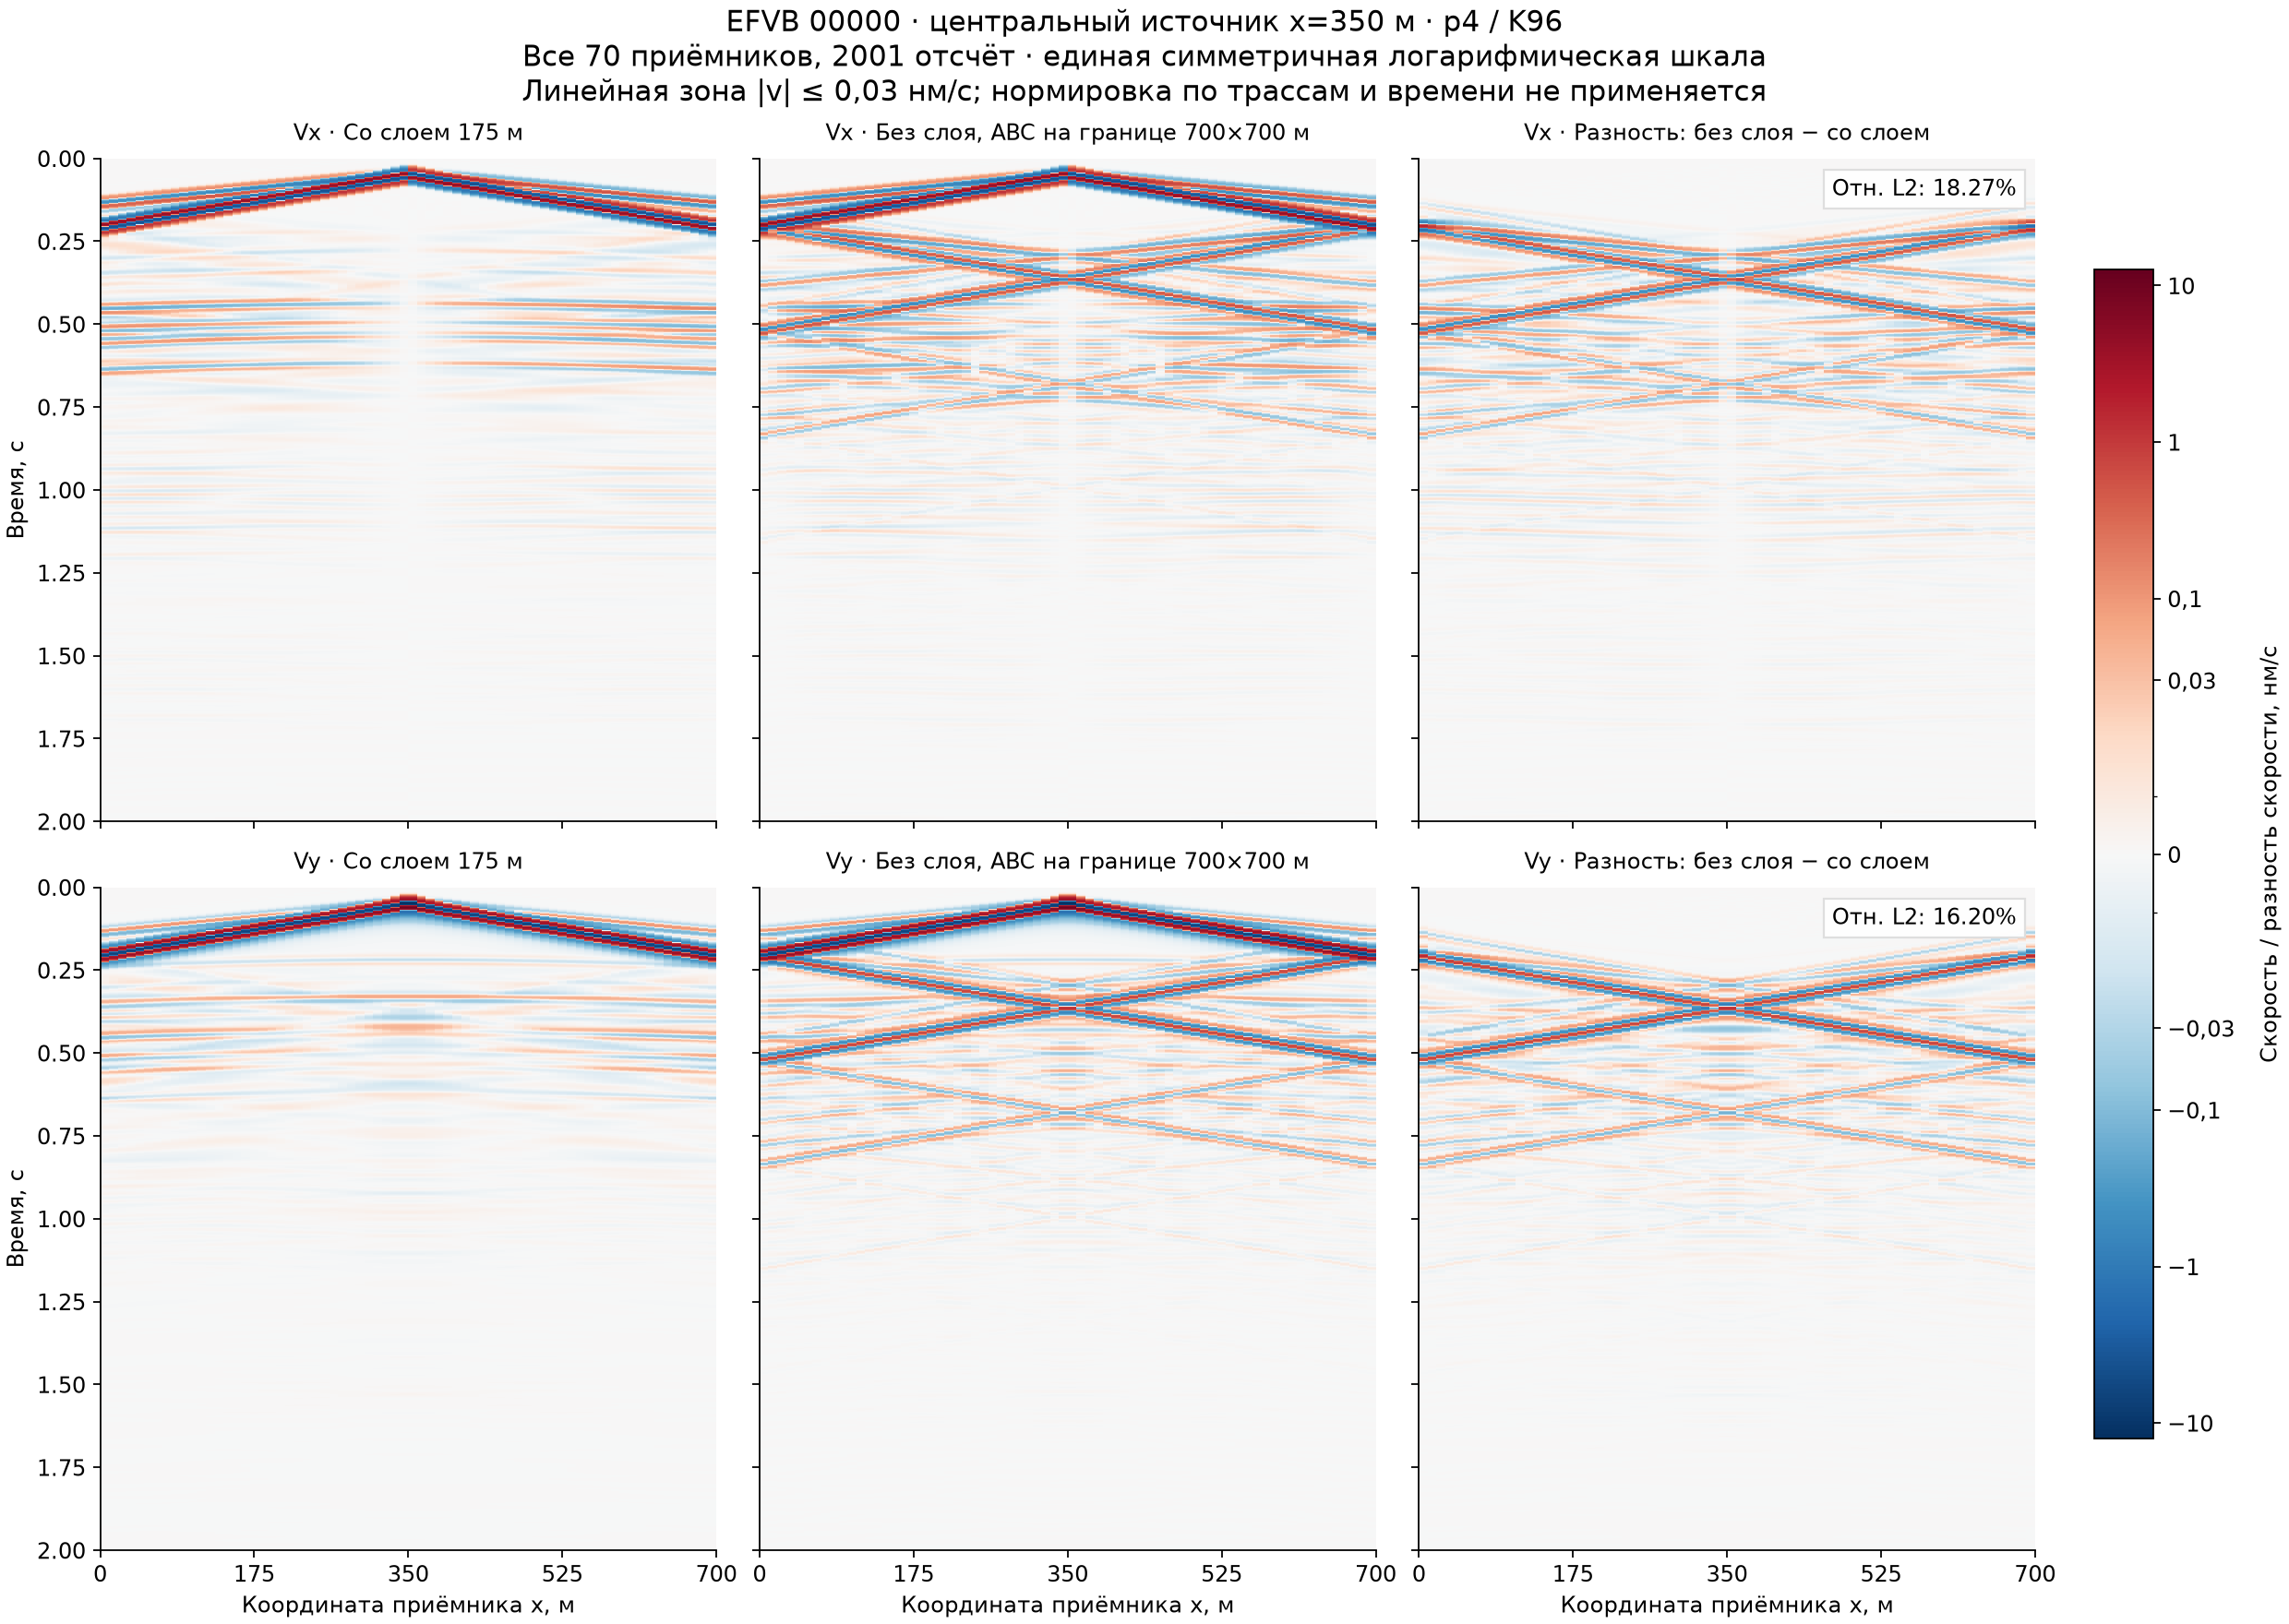

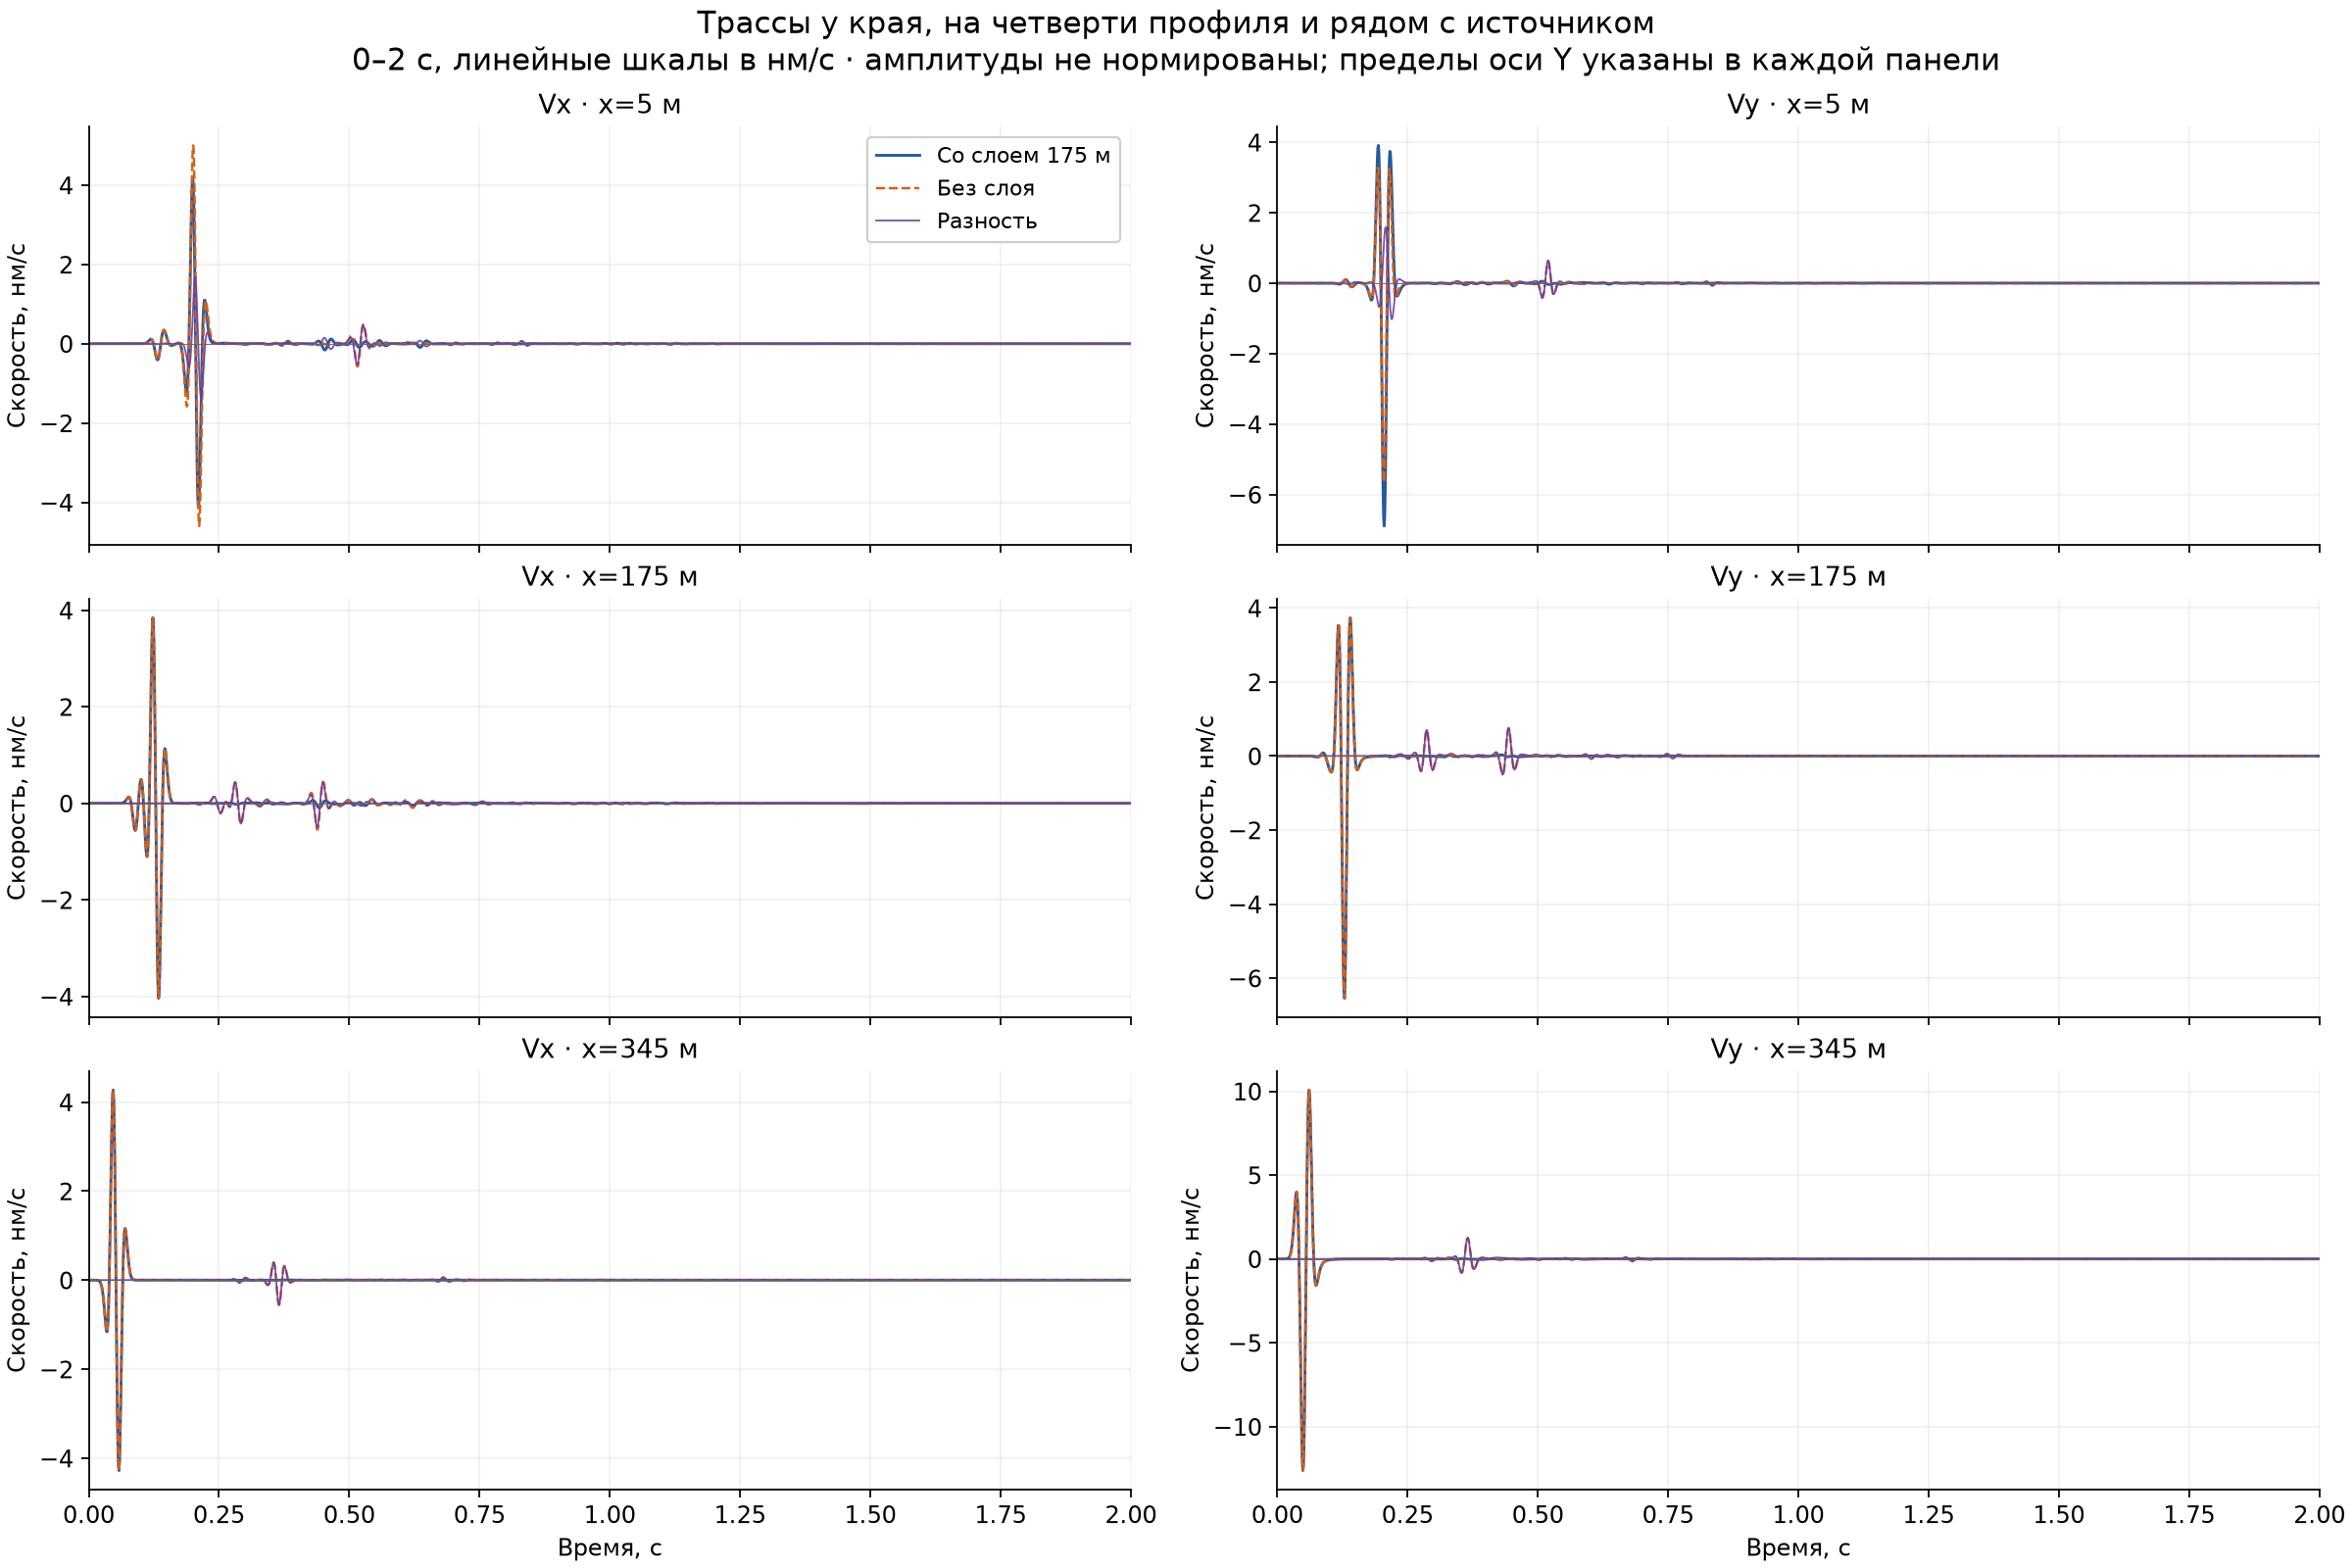

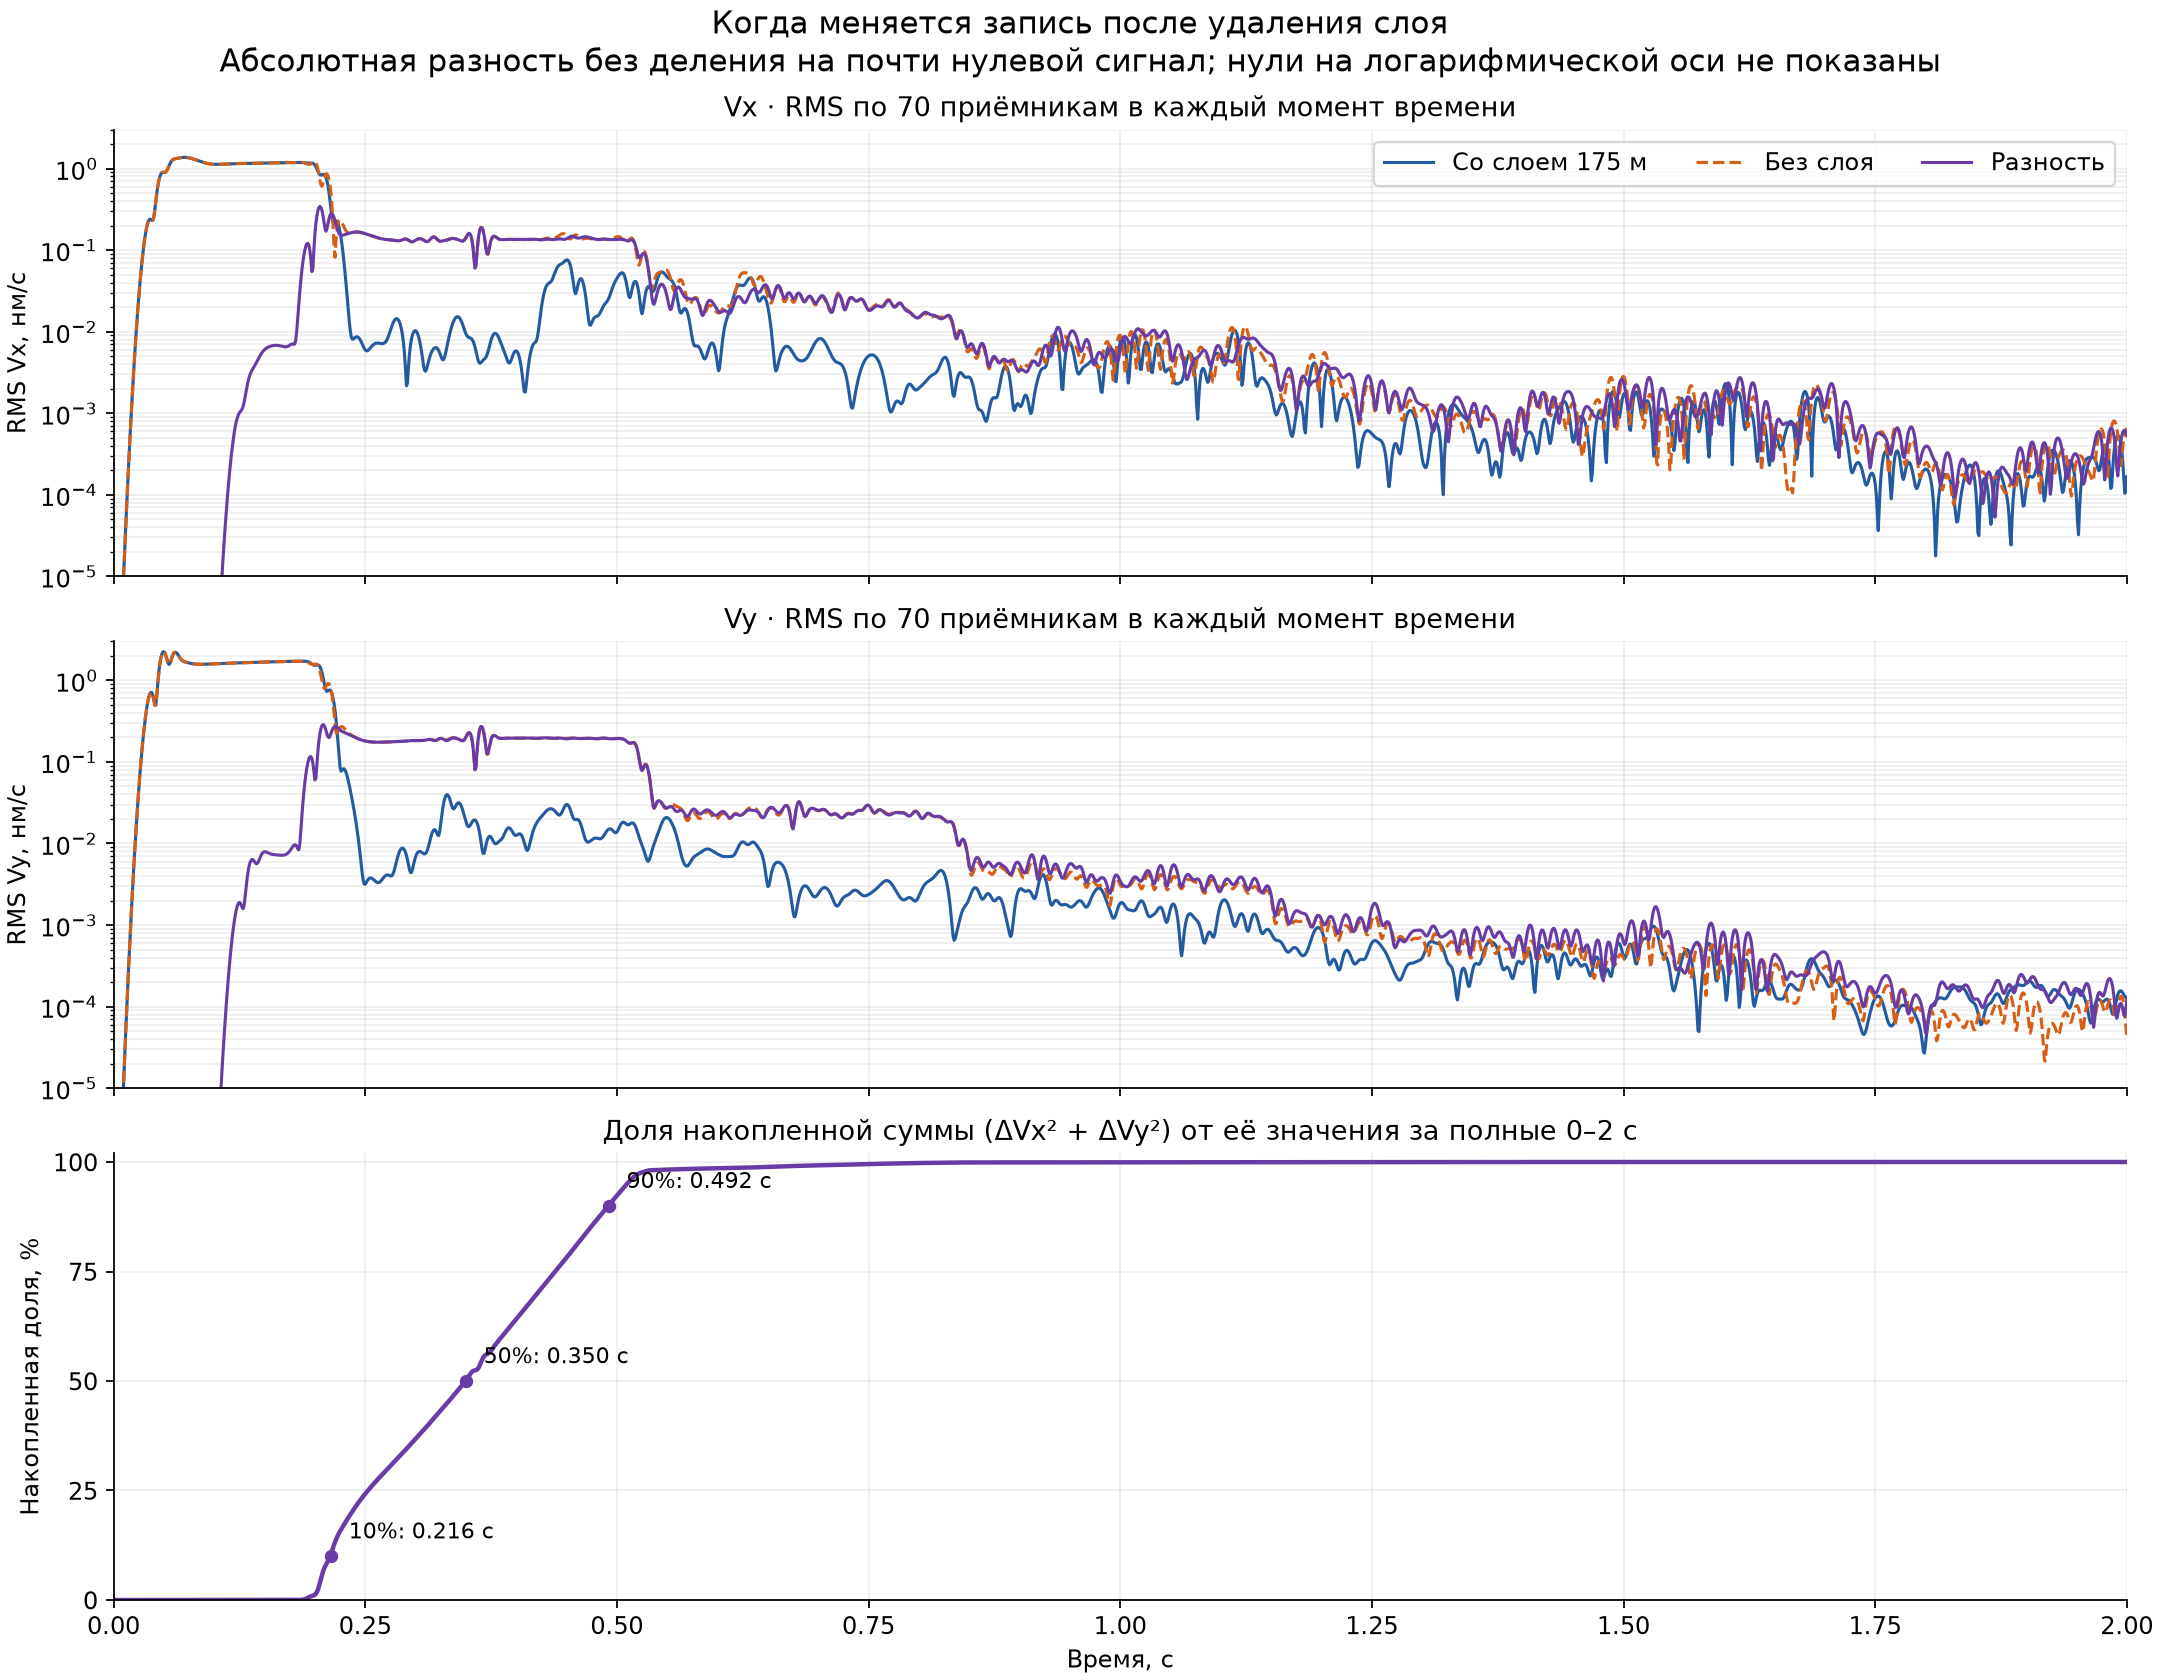

In [19]:
velocity_visualization_root = chapter14_root / "velocity_visualization_v1"
velocity_image_root = PROJECT_ROOT / "img/dev_1_4_server_preparation/velocity_comparison_v1"
velocity_seismograms = read_json(velocity_visualization_root / "seismograms.json")
assert velocity_seismograms["status"] == "completed"
print("Разность полных записей:", velocity_seismograms["full_window_metrics"])
display(Image(filename=str(velocity_image_root / "seismograms.png"), width=1200))
display(Image(filename=str(velocity_image_root / "traces.png"), width=1200))
display(Image(filename=str(velocity_image_root / "difference_over_time.png"), width=1100))

В прежних замерах времени поля всех узлов отсутствовали, поэтому для анимаций выполнен отдельный повтор обоих вариантов с Vx/Vy через 0,01 с, включая t=0 и t=2 с. По 201 кадру float64 сохраняются потоково в NPY; исходные сейсмограммы и результаты измерения времени не перезаписываются. Одновременно записываются прежние 70 приёмников через 0,001 с. Срезы всех узлов сверяются с этими приёмниками в общие моменты времени, а полные повторённые записи — с историческими опытами. Время с дополнительным выводом полей не подменяет замер surface-only.

Три ролика показывают модуль скорости в полных доменах, Vx/Vy со знаком и сравнение основной области с модулем разности векторов. Последняя величина вычисляется в соответствующих SEM-узлах до выбора пикселей:

$$
\left|\Delta \mathbf{v}\right| = \sqrt{(V_{x,\mathrm{без}}-V_{x,\mathrm{слой}})^2+(V_{y,\mathrm{без}}-V_{y,\mathrm{слой}})^2}.
$$

Цветовые пределы фиксируются по всем кадрам обоих вариантов: log-шкала для модуля и разности, симметричная log-шкала для компонент. Серое означает отсутствие расчётной области, а не нулевую скорость. Все 201 кадр воспроизводятся при 25 кадрах/с: 8,04 с видео, четырёхкратное замедление между физическими кадрами. Отображение использует ближайший SEM-узел к регулярному пикселю; исходные поля всех узлов сохранены отдельно. Пространственного или временного сглаживания для вычисления разности нет.

padded поля: [201, 589541, 2] ; проверка повтора: {'relative_l2': 9.318255298197008e-13, 'error_l2_m_s': 2.0717552772734875e-19, 'reference_l2_m_s': 2.223329594408464e-07, 'max_abs_m_s': 4.819981429346492e-21, 'rms_error_m_s': 3.9142710124310895e-22, 'rms_reference_m_s': 4.2006479616291043e-10, 'rms_new_m_s': 4.2006479616291296e-10}
core поля: [201, 314721, 2] ; проверка повтора: {'relative_l2': 1.1081225839294904e-12, 'error_l2_m_s': 2.490149524595444e-19, 'reference_l2_m_s': 2.2471787514384704e-07, 'max_abs_m_s': 5.05159200086134e-21, 'rms_error_m_s': 4.704764219821657e-22, 'rms_reference_m_s': 4.2457073685279387e-10, 'rms_new_m_s': 4.245707368527957e-10}
Шкалы анимаций: {'speed_and_vector_difference_log_limits_m_s': [2.6098114034523637e-13, 2.6098114034523633e-08], 'components_symlog_limits_m_s': [-2.6098114034523633e-08, 2.6098114034523633e-08], 'components_linear_threshold_m_s': 2.6098114034523633e-11, 'policy': 'One fixed physical scale across both variants, every frame and the v

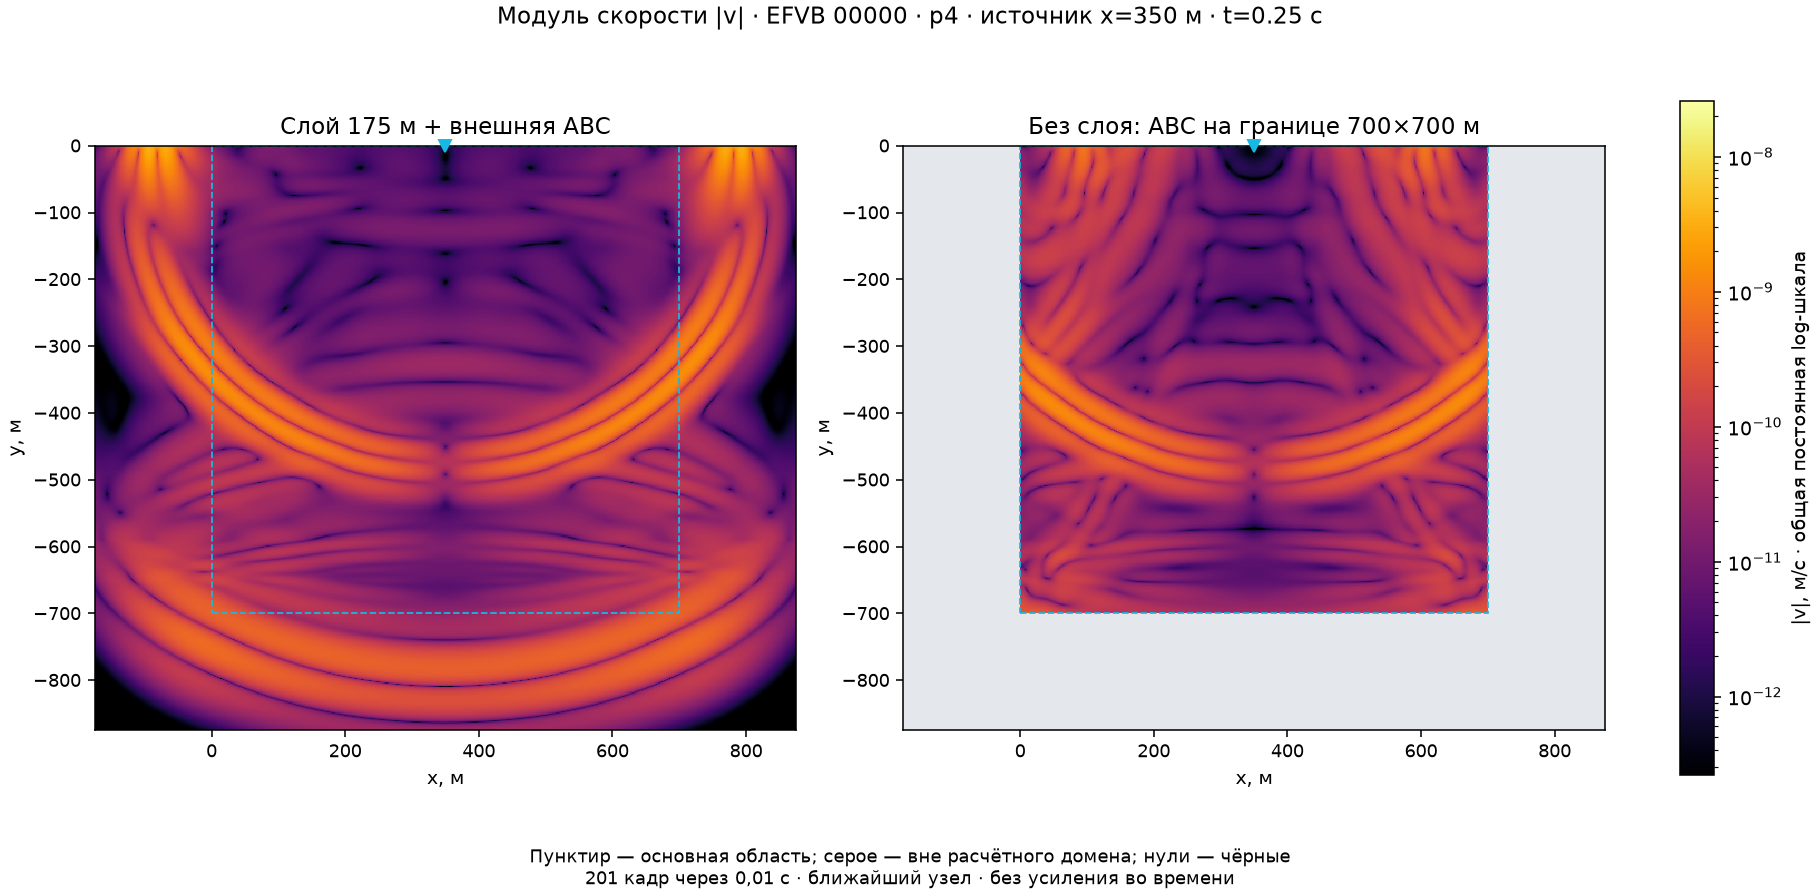

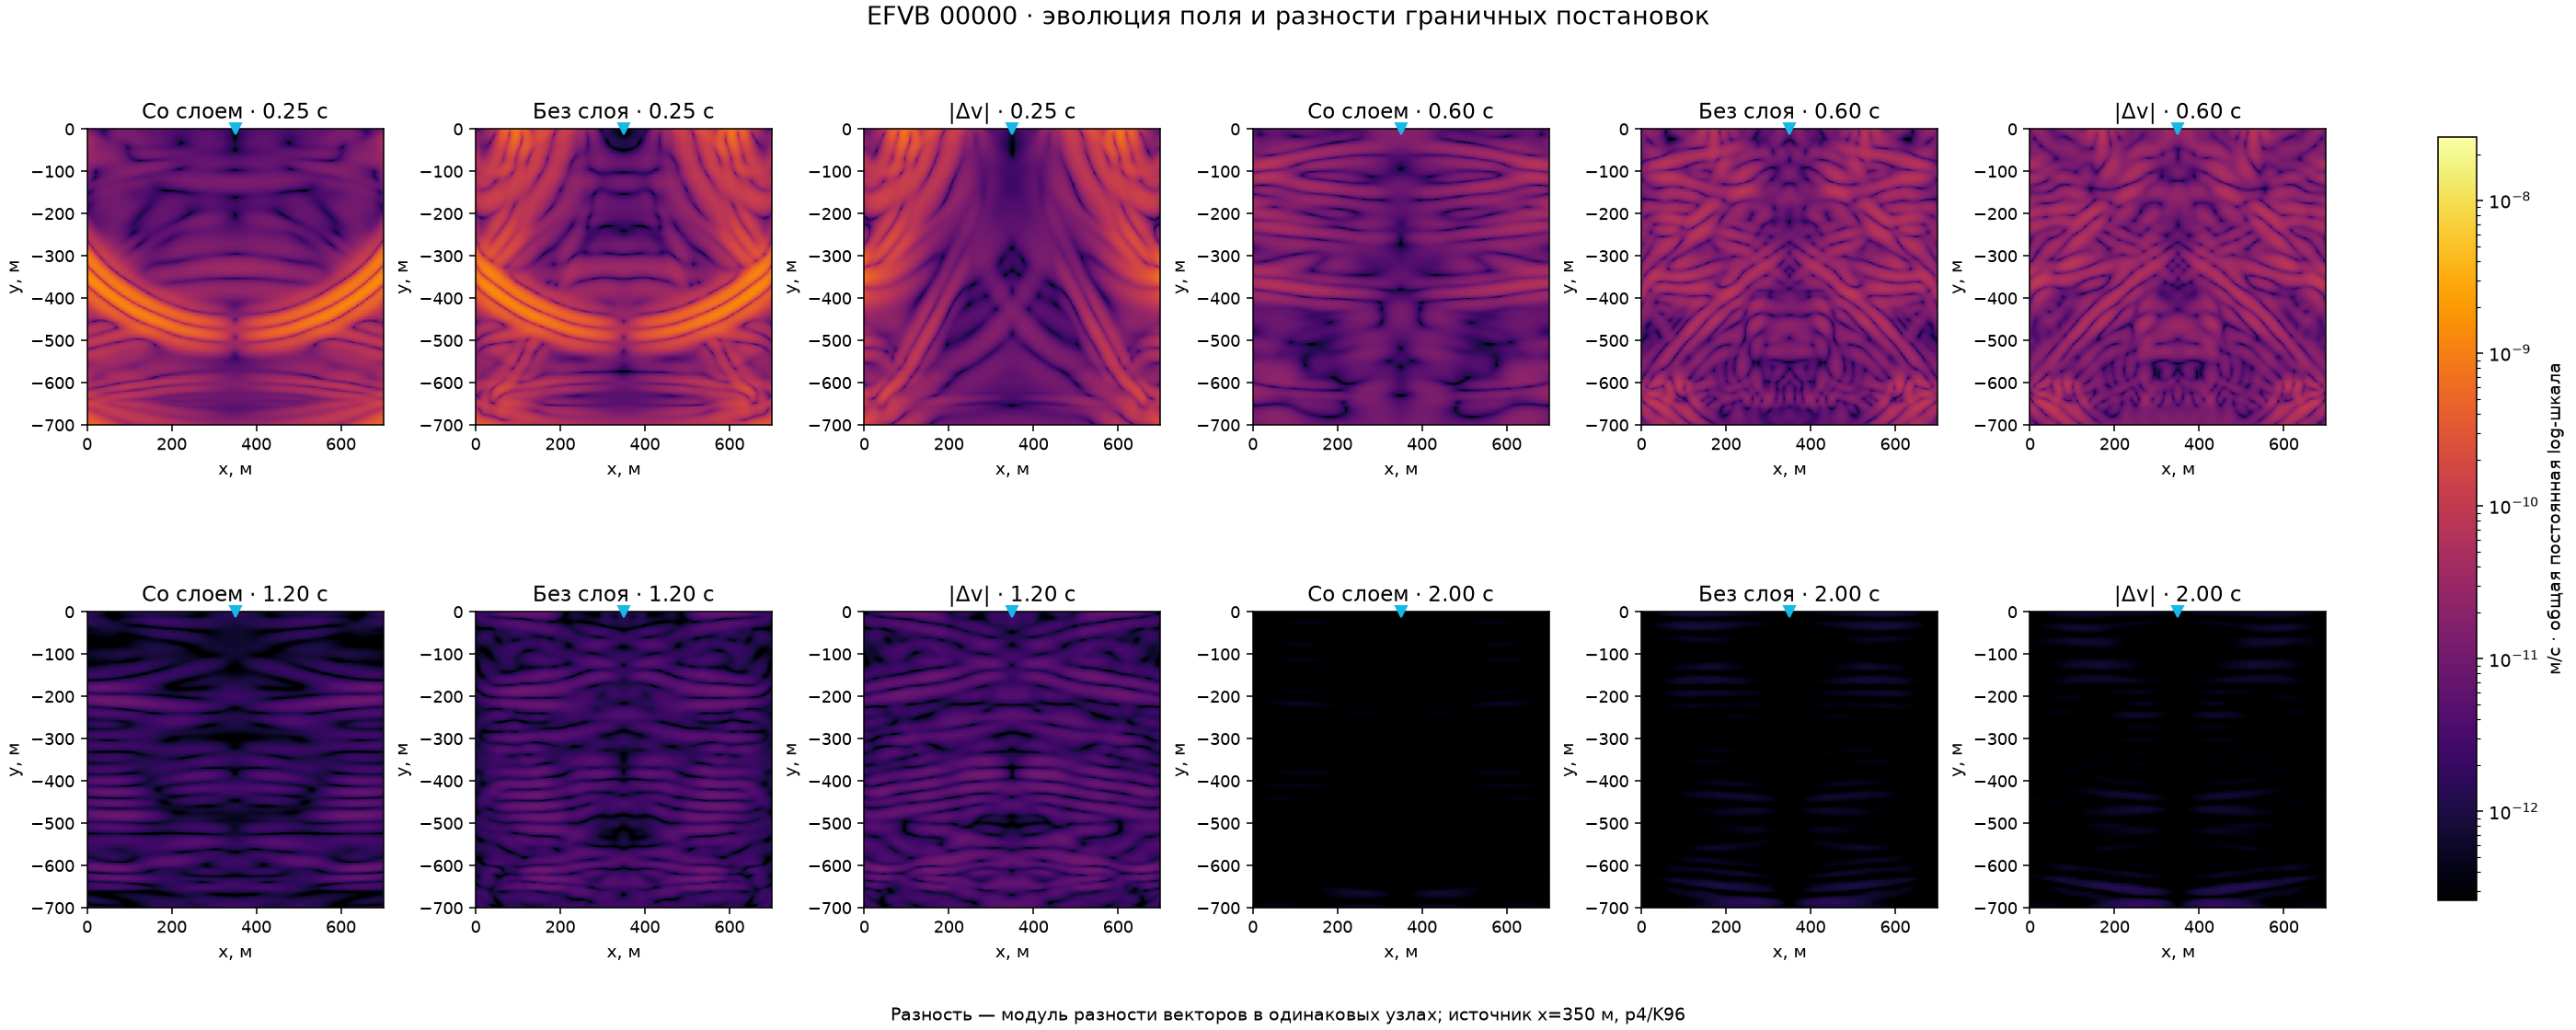

In [20]:
velocity_fields_root = chapter14_root / "velocity_fields_3060_v1"
for velocity_variant in ("padded", "core"):
    velocity_run = read_json(velocity_fields_root / velocity_variant / "metadata.json")
    velocity_repeat = read_json(velocity_fields_root / f"{velocity_variant}_repeat_check.json")
    assert velocity_run["status"] == "completed" and velocity_repeat["status"] == "passed"
    assert mapping(velocity_run["recorded_counts"])["fields"] == 201
    assert velocity_repeat["all_node_surface_values_exact"] is True
    print(velocity_variant, "поля:", velocity_run["field_shape"], "; проверка повтора:", velocity_repeat["metrics"])
velocity_animations = read_json(velocity_visualization_root / "animations.json")
assert velocity_animations["status"] == "completed" and velocity_animations["frame_count"] == 201
assert velocity_animations["physical_end_s"] == 2.0
print("Шкалы анимаций:", velocity_animations["color_scales"])
print("Сопоставление узлов:", velocity_animations["node_matching"])
for velocity_video_item in sequence(velocity_animations["videos"]):
    velocity_video = mapping(velocity_video_item)
    assert mapping(velocity_video["ffprobe"])["nb_read_frames"] == "201"
    print("Полный ролик:", (velocity_image_root / Path(str(velocity_video["path"])).name).relative_to(PROJECT_ROOT))
display(Image(filename=str(velocity_image_root / "speed_full_t025.png"), width=1200))
display(Image(filename=str(velocity_image_root / "speed_difference_montage.png"), width=1400))

### Вывод визуального сравнения

Удаление слоя даёт существенную экономию времени, но сопровождается дополнительными приходами на сейсмограммах. Общие шкалы позволяют увидеть разность амплитуд и пространственную эволюцию обоих вариантов без искусственного усиления отдельных кадров. Анимации охватывают полные 2 с; слабая поздняя часть не исключена из записи. Сравнение повторов подтверждает согласованность новой регистрации полей с прежними сейсмограммами, но не заменяет независимой оценки точности ABC или сходимости решателя.